# Postergación del etiquetado en una viña
### Planificación de embotellado y etiquetado bajo demanda incierta

Modelo MILP estocástico multietapa sobre un **árbol de 11 escenarios en 3 periodos**, resuelto con **PuLP + HiGHS**.

| Política | Idea |
|---|---|
| **A stock** *(caso base, lo que se hace hoy)* | Todo se embotella y etiqueta de una vez. |
| **Contra pedido** | No se guarda producto terminado: solo se despacha lo que ya se pidió. |
| **Híbrida** | Algunos productos se embotellan sin etiqueta y se etiquetan cuando se conoce la demanda. En esta entrega se usa **PL = 5** (las 5 etiquetas pueden postergarse). |

**Orden de la presentación**
1. Costo de las tres políticas
2. Caso base: a stock
3. Política híbrida (PL = 5)
4. Caso base vs. híbrida: KPIs
5. ¿Por qué la híbrida es mejor?
6. Conclusiones
7. Tiempos de resolución

*Anexo:* datos de la instancia, decisiones por nodo, todas las políticas (PL = 0…5) y sensibilidad a la capacidad (para la próxima entrega).

*Fuentes:* `formulacion_compacta.pdf` (modelo) y `Anexo a Datos.pdf` (instancia).

In [1]:
import importlib, time, datos, modelo
importlib.reload(datos); importlib.reload(modelo)
import pandas as pd
from IPython.display import display
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

---
## 1. ¿Cuánto cuesta cada política?
Costo esperado de las tres políticas en el caso base de capacidad (84 h por periodo). La escala es **logarítmica**: cada línea de la grilla es 10 veces la anterior.

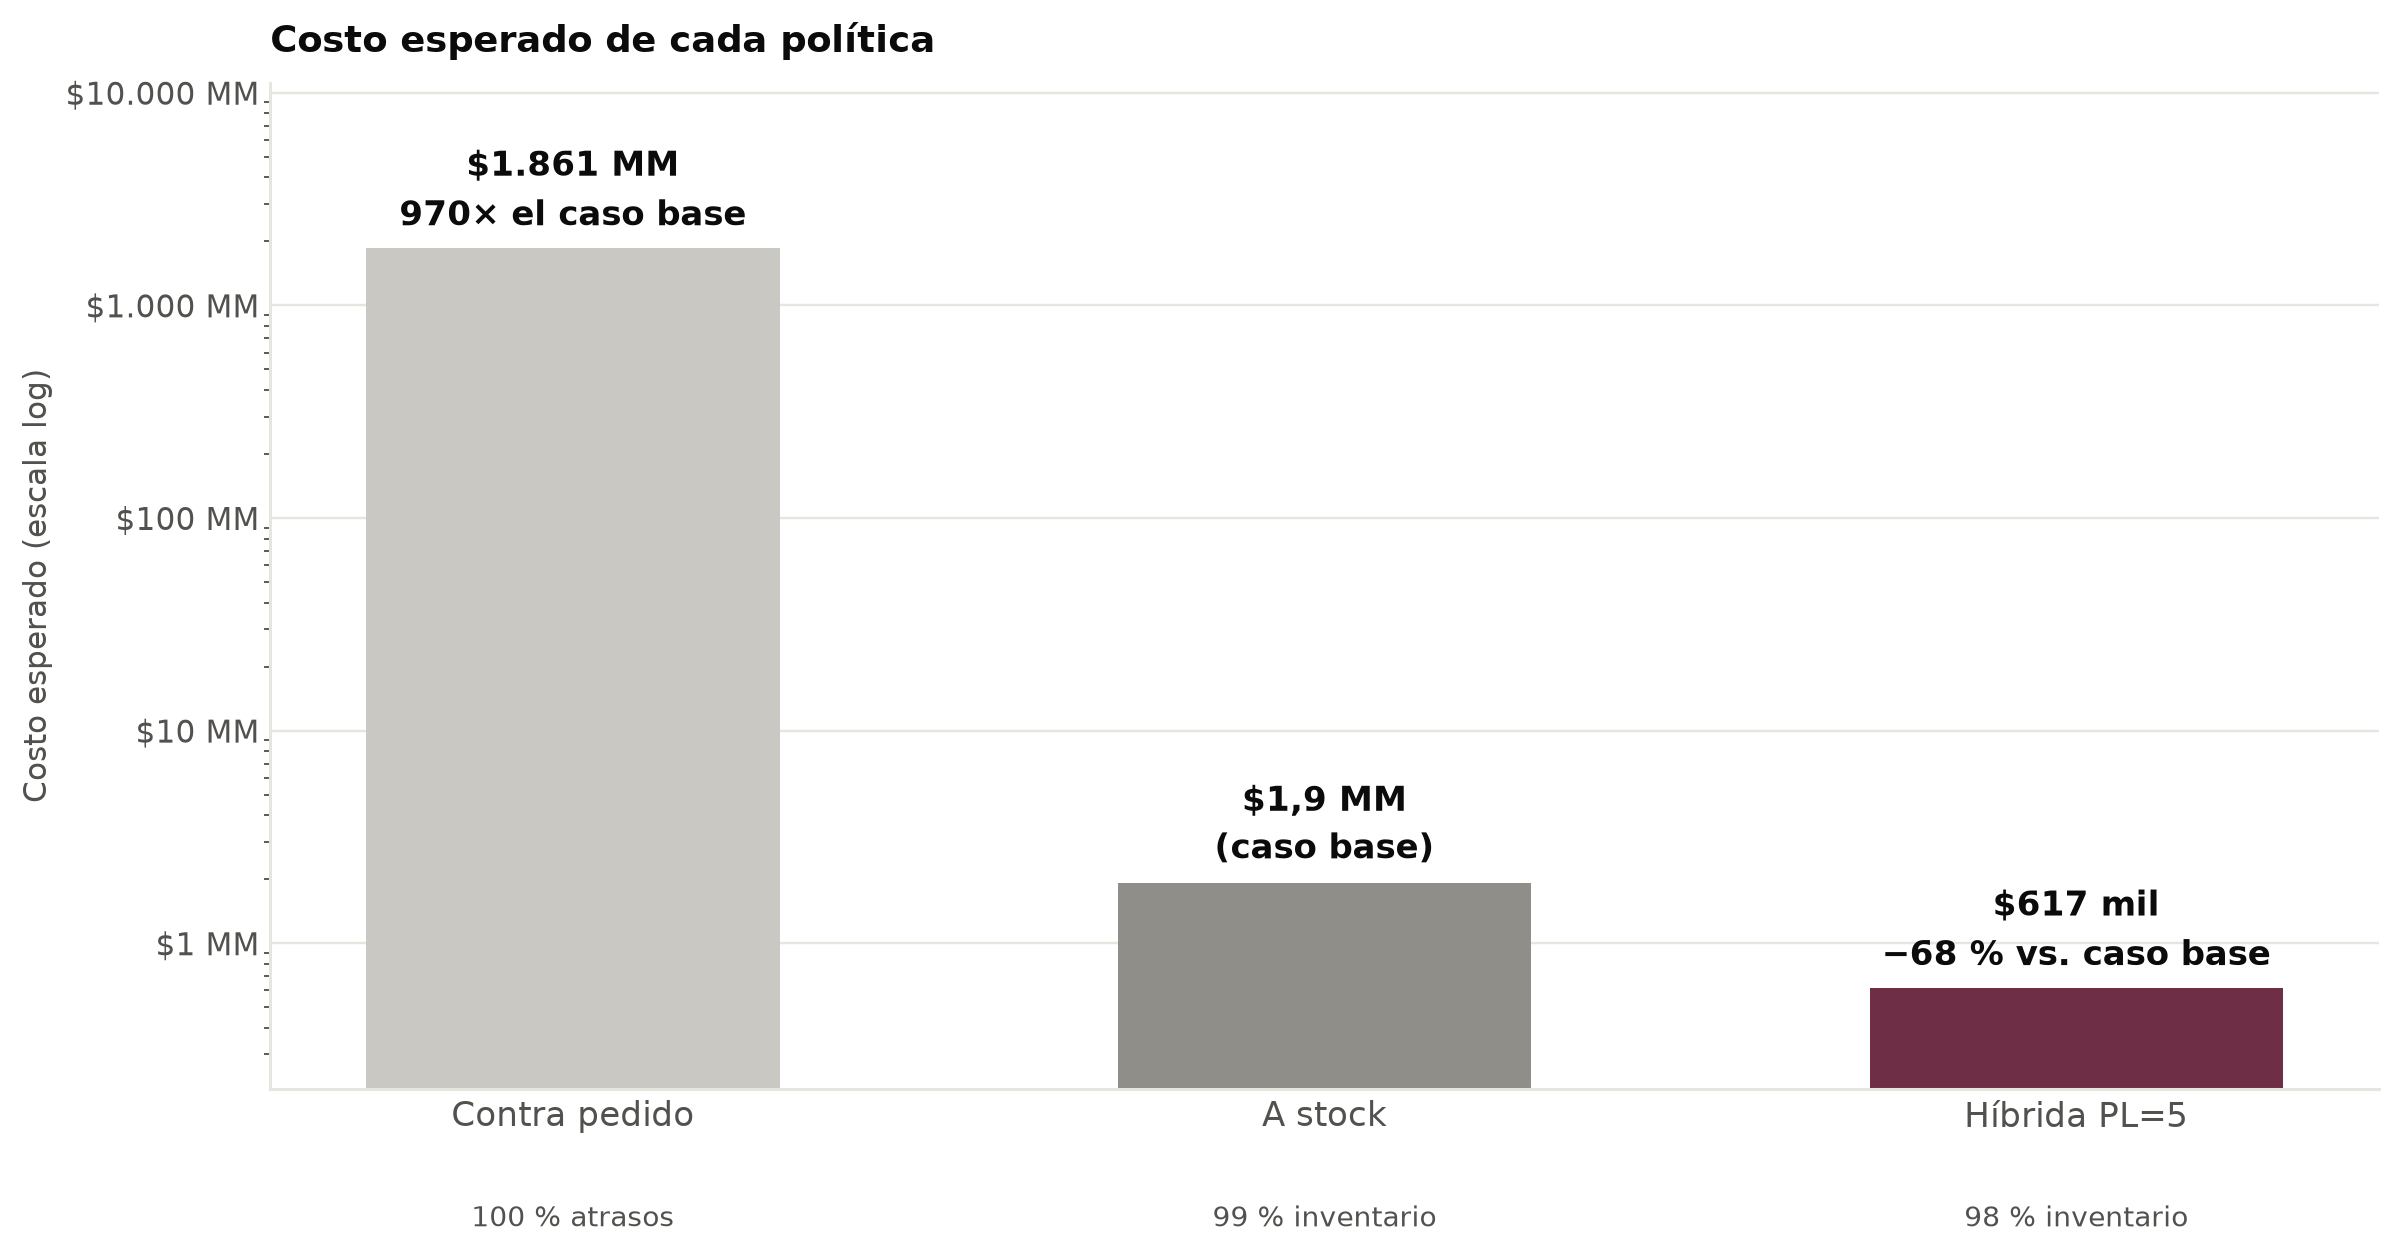

In [2]:
tabla = modelo.comparar_politicas()
modelo.graficar_politicas(tabla);

**Contra pedido cuesta unas 970 veces más que producir a stock**, y casi todo ese costo son atrasos (solo entrega a tiempo el 68,7 % de la demanda).

El problema no es la capacidad de la línea, sino el **rezago de un periodo del embotellado**. Lo que se embotella en un periodo recién está disponible en el siguiente. Si no se puede guardar producto terminado, en cada periodo solo se embotella lo que se venderá con seguridad en el siguiente, es decir, la demanda del escenario más bajo. Todo lo demás queda atrasado. Con **1.000 horas** de línea por periodo, contra pedido cuesta exactamente lo mismo (celda siguiente).

In [3]:
r = modelo.resolver(contra_pedido=True, T_prod=1000)
print(f"Contra pedido con 1.000 h por periodo: ${modelo._num(r['obj'])}  |  "
      f"nivel de servicio {modelo._pct(r['kpis']['Nivel de servicio'], 1)}")

Contra pedido con 1.000 h por periodo: $1.861.097.600  |  nivel de servicio 68,7 %


---
## 2. Caso base: producir a stock
Es lo que la viña hace hoy: cada botella se etiqueta al embotellarla, **antes de conocer la demanda** del periodo siguiente.
En el árbol, el color de cada nodo indica qué tan cargada está la línea, y dentro del nodo se lee su probabilidad (π), las horas usadas y el inventario al cierre.

Política: A stock  |  estado: Optimal  |  costo esperado: $1.918.302
  Set-ups $13.650  |  Inventario $1.904.652  |  Atrasos $0
  Productos postergables elegidos: ninguno
  Nivel de servicio 100,0 %  |  Utilización media 43 %  |  Set-ups esperados 9,1  |  Inventario promedio 42.326 botellas


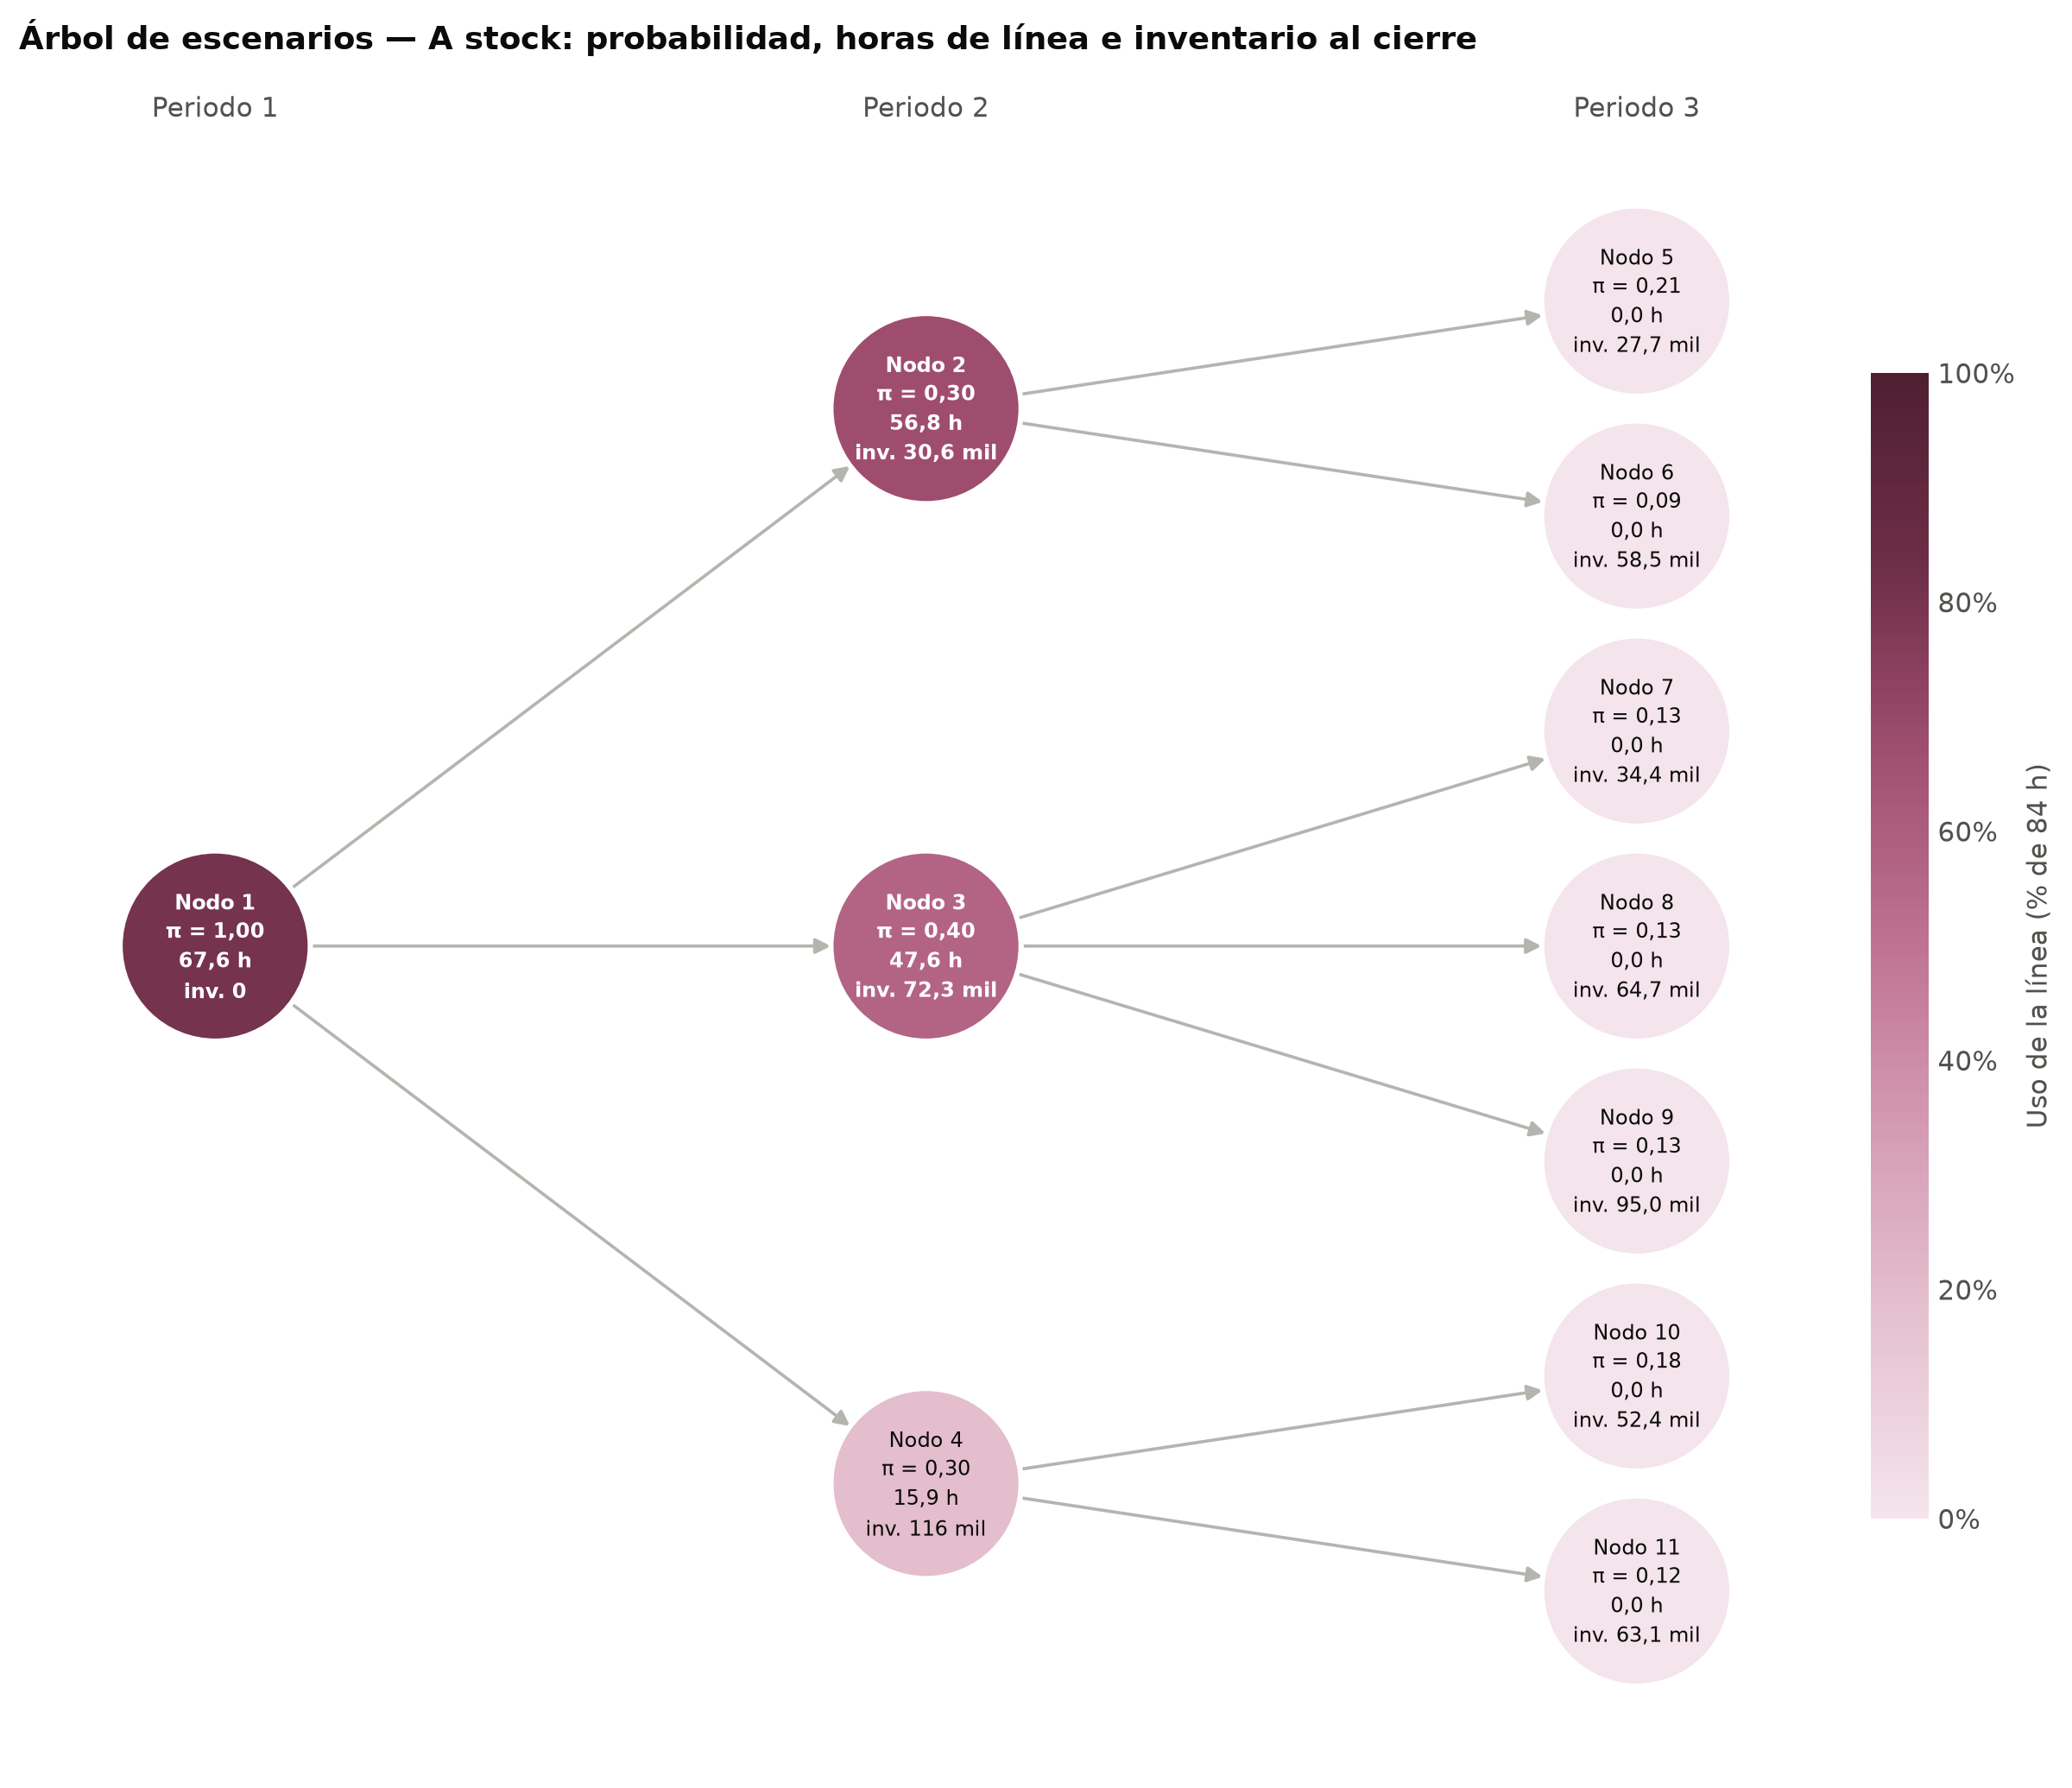

In [4]:
res_base = modelo.resolver(PL=0)
modelo.resumen(res_base)
modelo.graficar_arbol(res_base);

- **Toda la producción se hace en los periodos 1 y 2**, con el nodo 1 al 80 % de su capacidad. En el periodo 3 la línea queda detenida.
- Como las etiquetas se deciden antes de conocer la demanda, **sobran botellas terminadas**, sobre todo en los escenarios de demanda baja: 116 mil en el nodo 4 y 95 mil en el nodo 9.

---
## 3. Política híbrida (PL = 5)
Las botellas se embotellan **sin etiqueta** y se etiquetan en el periodo siguiente, **una vez conocida la demanda**.

Política: Híbrida PL=5  |  estado: Optimal  |  costo esperado: $617.164
  Set-ups $10.550  |  Inventario $606.614  |  Atrasos $0
  Productos postergables elegidos: Vino 1 · Etiq. 1, Vino 1 · Etiq. 2, Vino 1 · Etiq. 3, Vino 2 · Etiq. 1, Vino 2 · Etiq. 2
  Nivel de servicio 100,0 %  |  Utilización media 53 %  |  Set-ups esperados 13,7  |  Inventario promedio 20.220 botellas


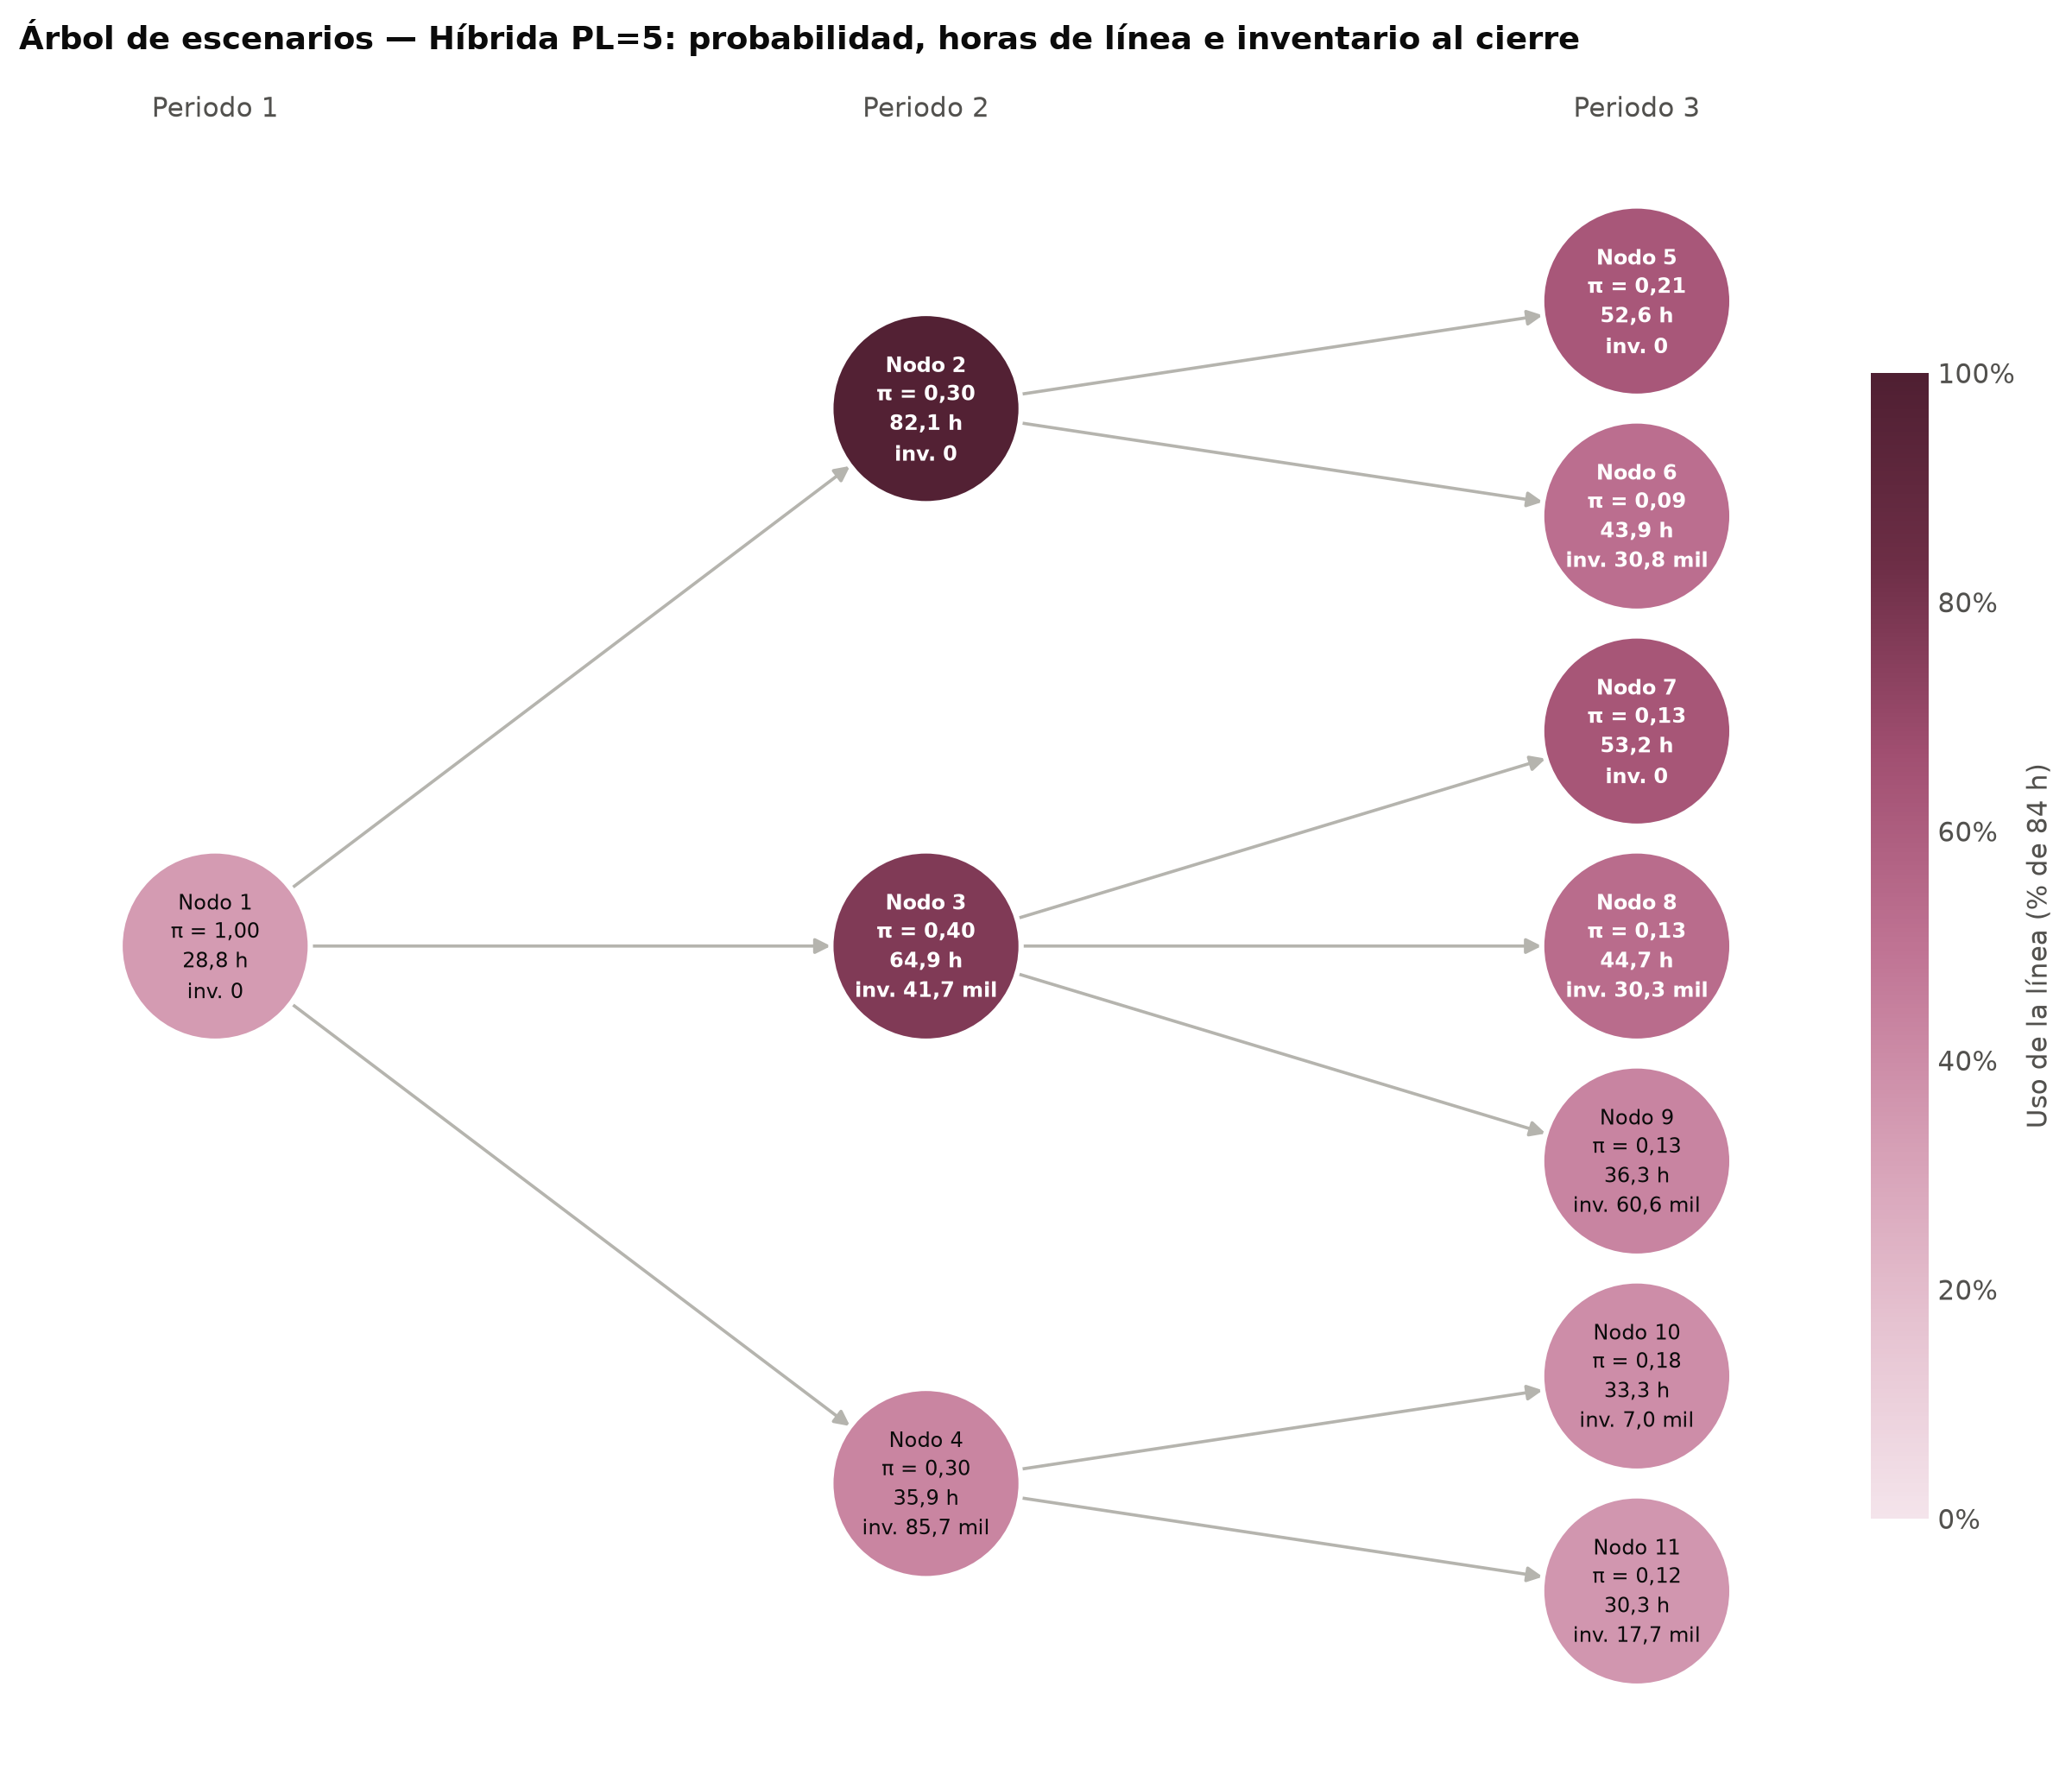

In [5]:
res_hib = modelo.resolver(PL=5)
modelo.resumen(res_hib)
modelo.graficar_arbol(res_hib);

- **La carga de la línea se reparte** en los tres periodos. El nodo 1 baja al 34 % porque embotellar sin etiqueta es el doble de rápido, y en el periodo 3 la línea trabaja etiquetando lo que se pidió.
- **El nodo 2** (demanda alta) llega al 98 % de su capacidad, que es el punto más exigido del plan.
- Lo que sobra queda **sin etiqueta**: es más barato de guardar (\$10 vs. \$15 por botella) y todavía puede convertirse en cualquier etiqueta de su vino.

**Plan del primer periodo (decisión que se ejecuta hoy)**

In [6]:
modelo.tabla_plan_inicial(res_hib)

,Demanda,Botellas a producir,Postergable
Producto,,,
Vino 1 · Etiq. 1,23.525,0,Sí
Vino 1 · Etiq. 2,24.328,0,Sí
Vino 1 · Etiq. 3,20.368,0,Sí
Vino 2 · Etiq. 1,21.080,0,Sí
Vino 2 · Etiq. 2,22.991,0,Sí
Vino 1 · sin etiqueta,,106.552,
Vino 2 · sin etiqueta,,77.435,


---
## 4. Caso base vs. híbrida: KPIs operativos
Valores esperados, ponderados por la probabilidad de cada escenario. Cada panel tiene su propia escala. Las variaciones de los KPIs que ya son porcentajes se expresan en **puntos porcentuales (pp)**.

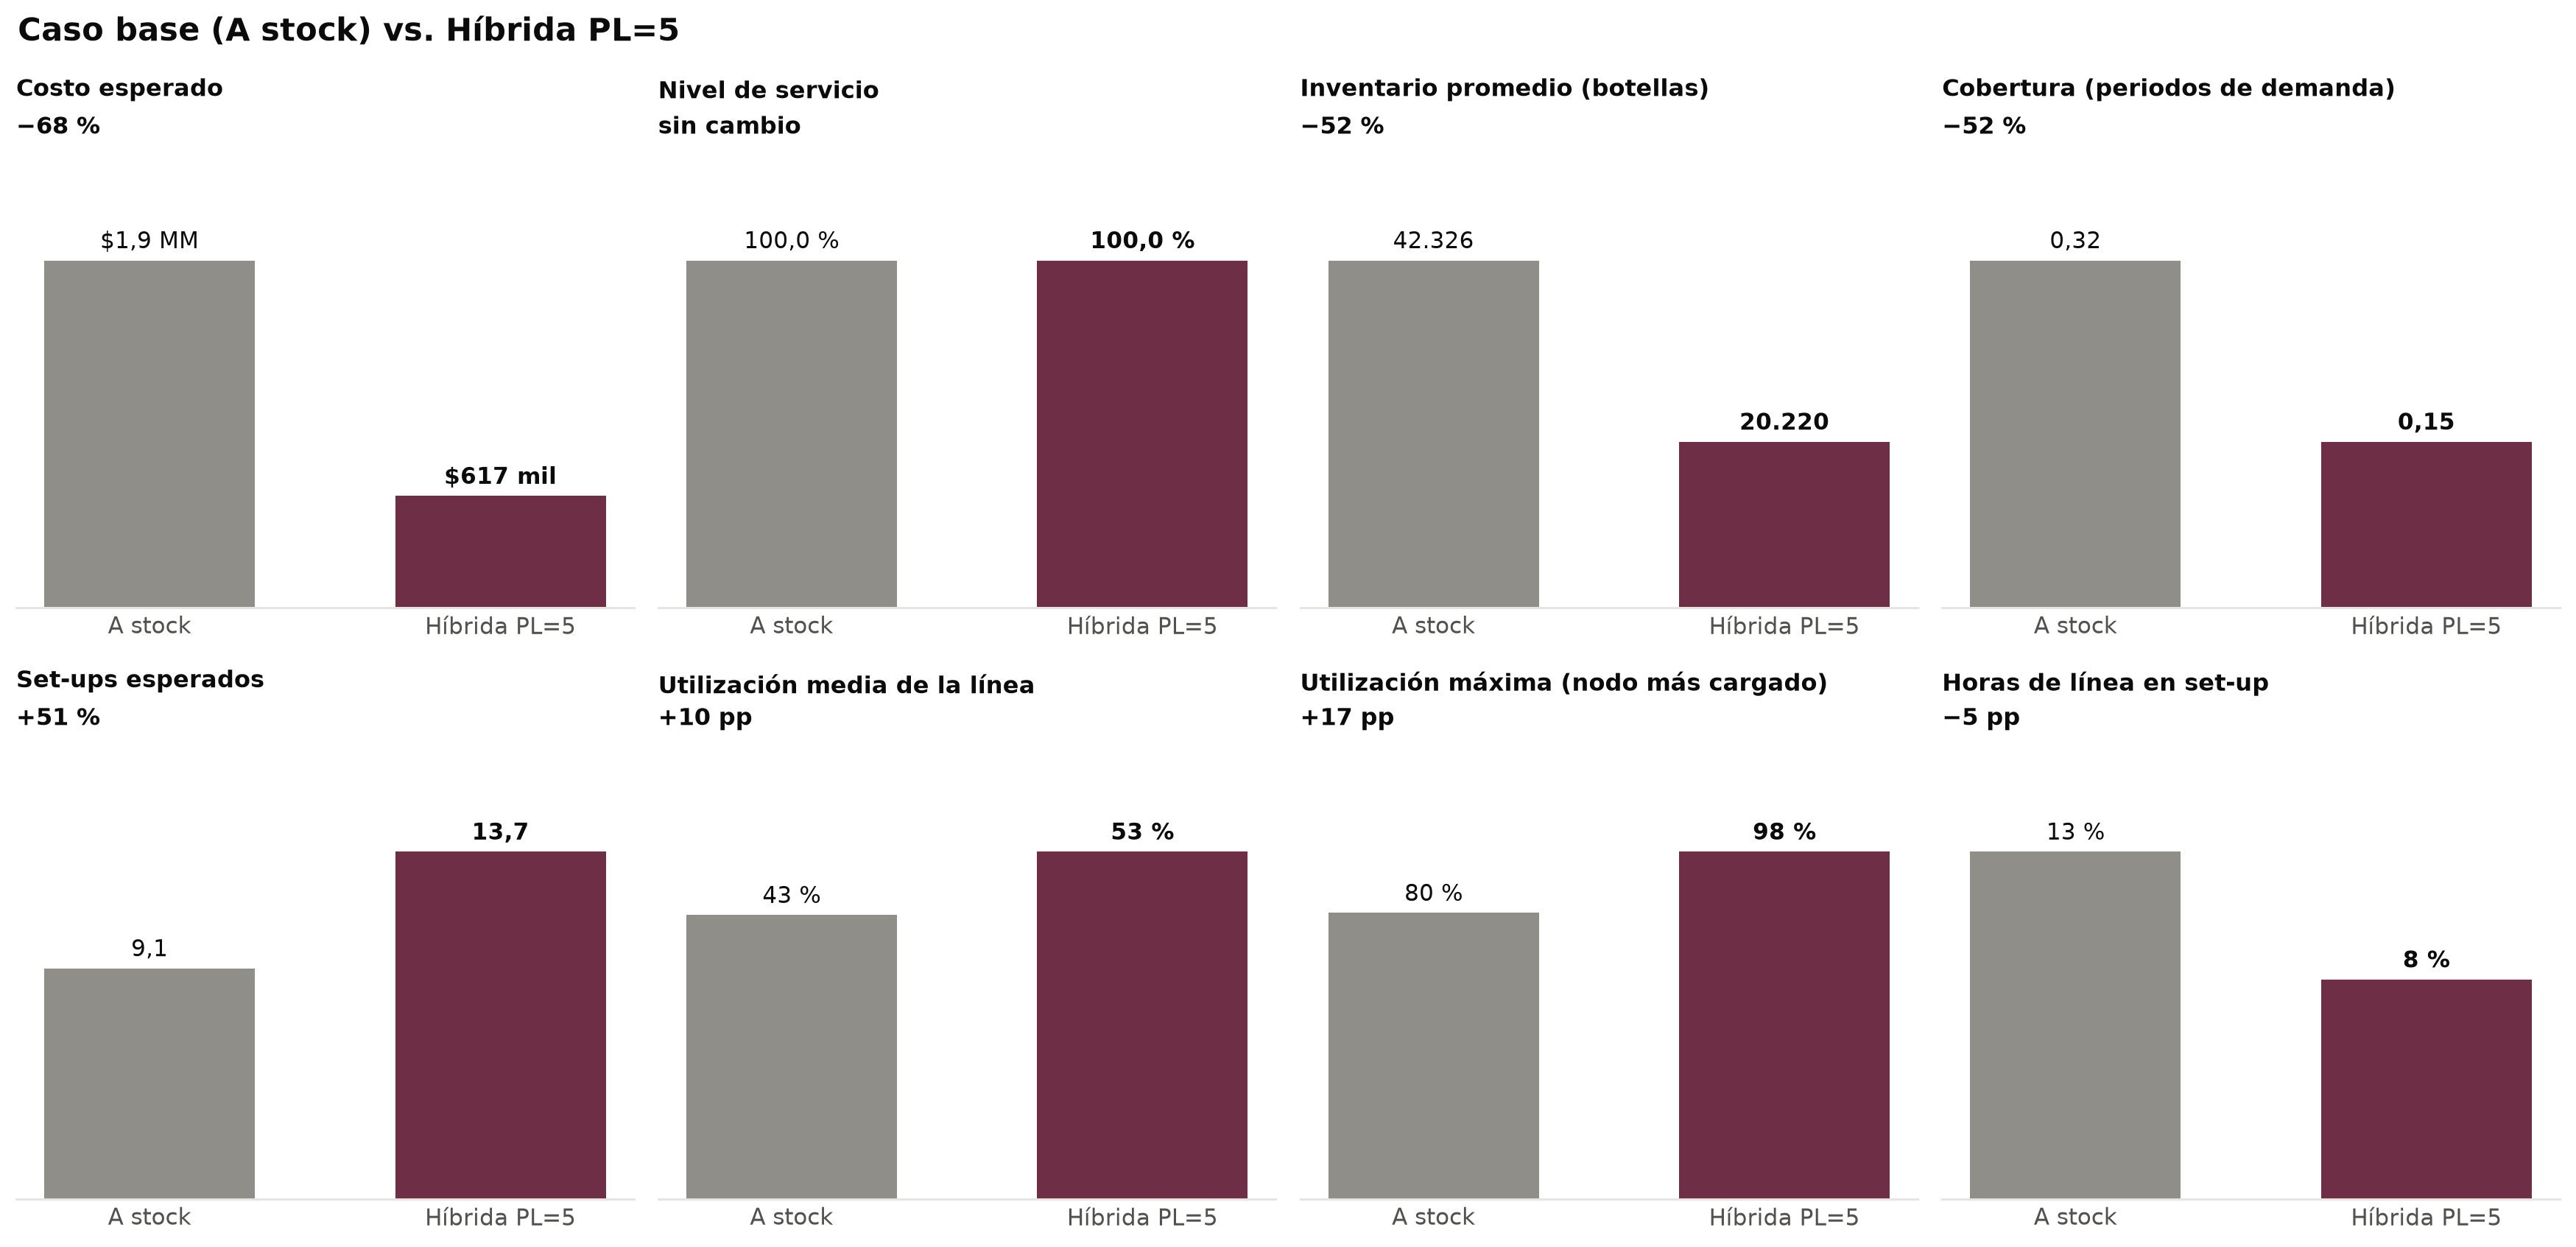

In [7]:
modelo.graficar_base_vs_alternativa(tabla, base='A stock', alt='Híbrida PL=5');

In [8]:
modelo.tabla_base_vs_alternativa(tabla, base='A stock', alt='Híbrida PL=5')

,A stock,Híbrida PL=5,Variación
KPI,,,
Costo esperado,"$1,9 MM",$617 mil,−68 %
Nivel de servicio,"100,0 %","100,0 %",sin cambio
Inventario promedio (botellas),42.326,20.220,−52 %
Cobertura (periodos de demanda),"0,32","0,15",−52 %
Set-ups esperados,"9,1","13,7",+51 %
Utilización media de la línea,43 %,53 %,+10 pp
Utilización máxima (nodo más cargado),80 %,98 %,+17 pp
Horas de línea en set-up,13 %,8 %,−5 pp
Costo: set-up embotellado sin etiqueta,$0,$5.550,nuevo


| KPI | Definición |
|---|---|
| **Nivel de servicio** | % de la demanda entregada en el mismo periodo en que se pide (*fill rate*). |
| **Inventario promedio** | Botellas guardadas al cierre de cada periodo (sin etiqueta y terminadas), en promedio. |
| **Cobertura** | Inventario promedio ÷ demanda promedio por periodo. |
| **Set-ups esperados** | Número de set-ups de todos los tipos en los 3 periodos. |
| **Utilización media / máxima** | Horas usadas ÷ horas disponibles: el promedio por periodo y el nodo más cargado. |
| **Horas en set-up** | % de las horas usadas que se van en set-ups. |

---
## 5. ¿Por qué la híbrida es mejor?
### 5.1 De dónde viene el ahorro
Paso a paso, cómo se llega del costo del caso base al de la híbrida, componente por componente de la función objetivo.

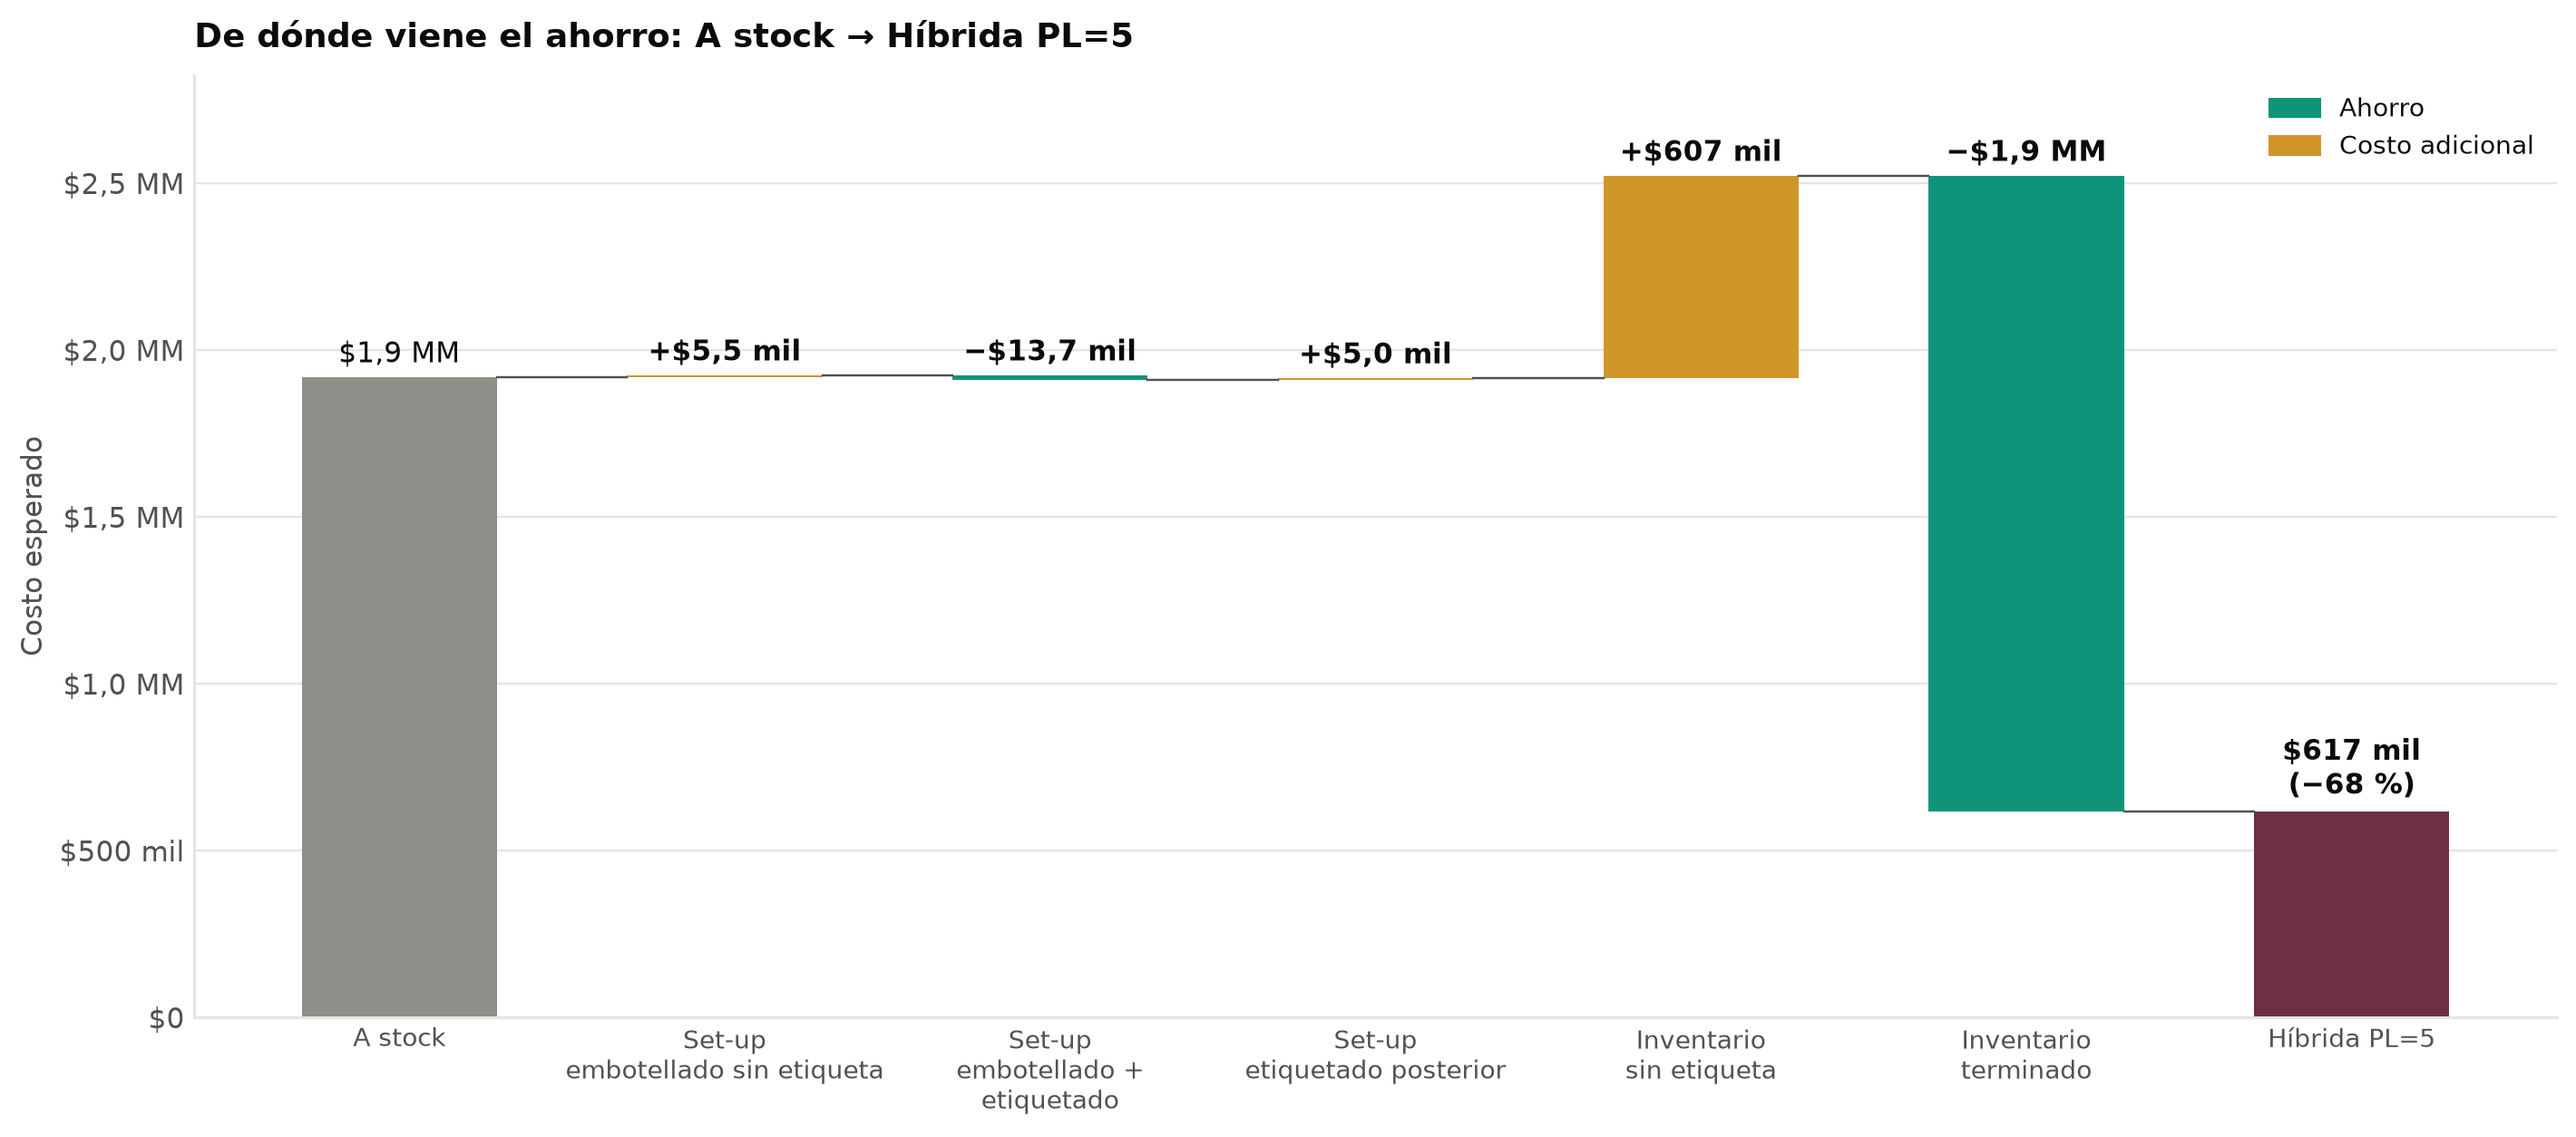

In [9]:
modelo.graficar_puente_costos(tabla, base='A stock', alt='Híbrida PL=5');

Casi todo el ahorro viene de **dejar de guardar producto terminado** (−\$1,9 MM). A cambio, se guardan botellas sin etiqueta (+\$607 mil). El efecto neto en set-ups es casi nulo (−\$3 mil): se pagan nuevos set-ups de etiquetado posterior, pero se eliminan los de embotellado acoplado.

### 5.2 Menos inventario en cada escenario
Inventario al cierre de cada nodo. Con *a stock* todo lo guardado está etiquetado, y con la híbrida todo está sin etiqueta.

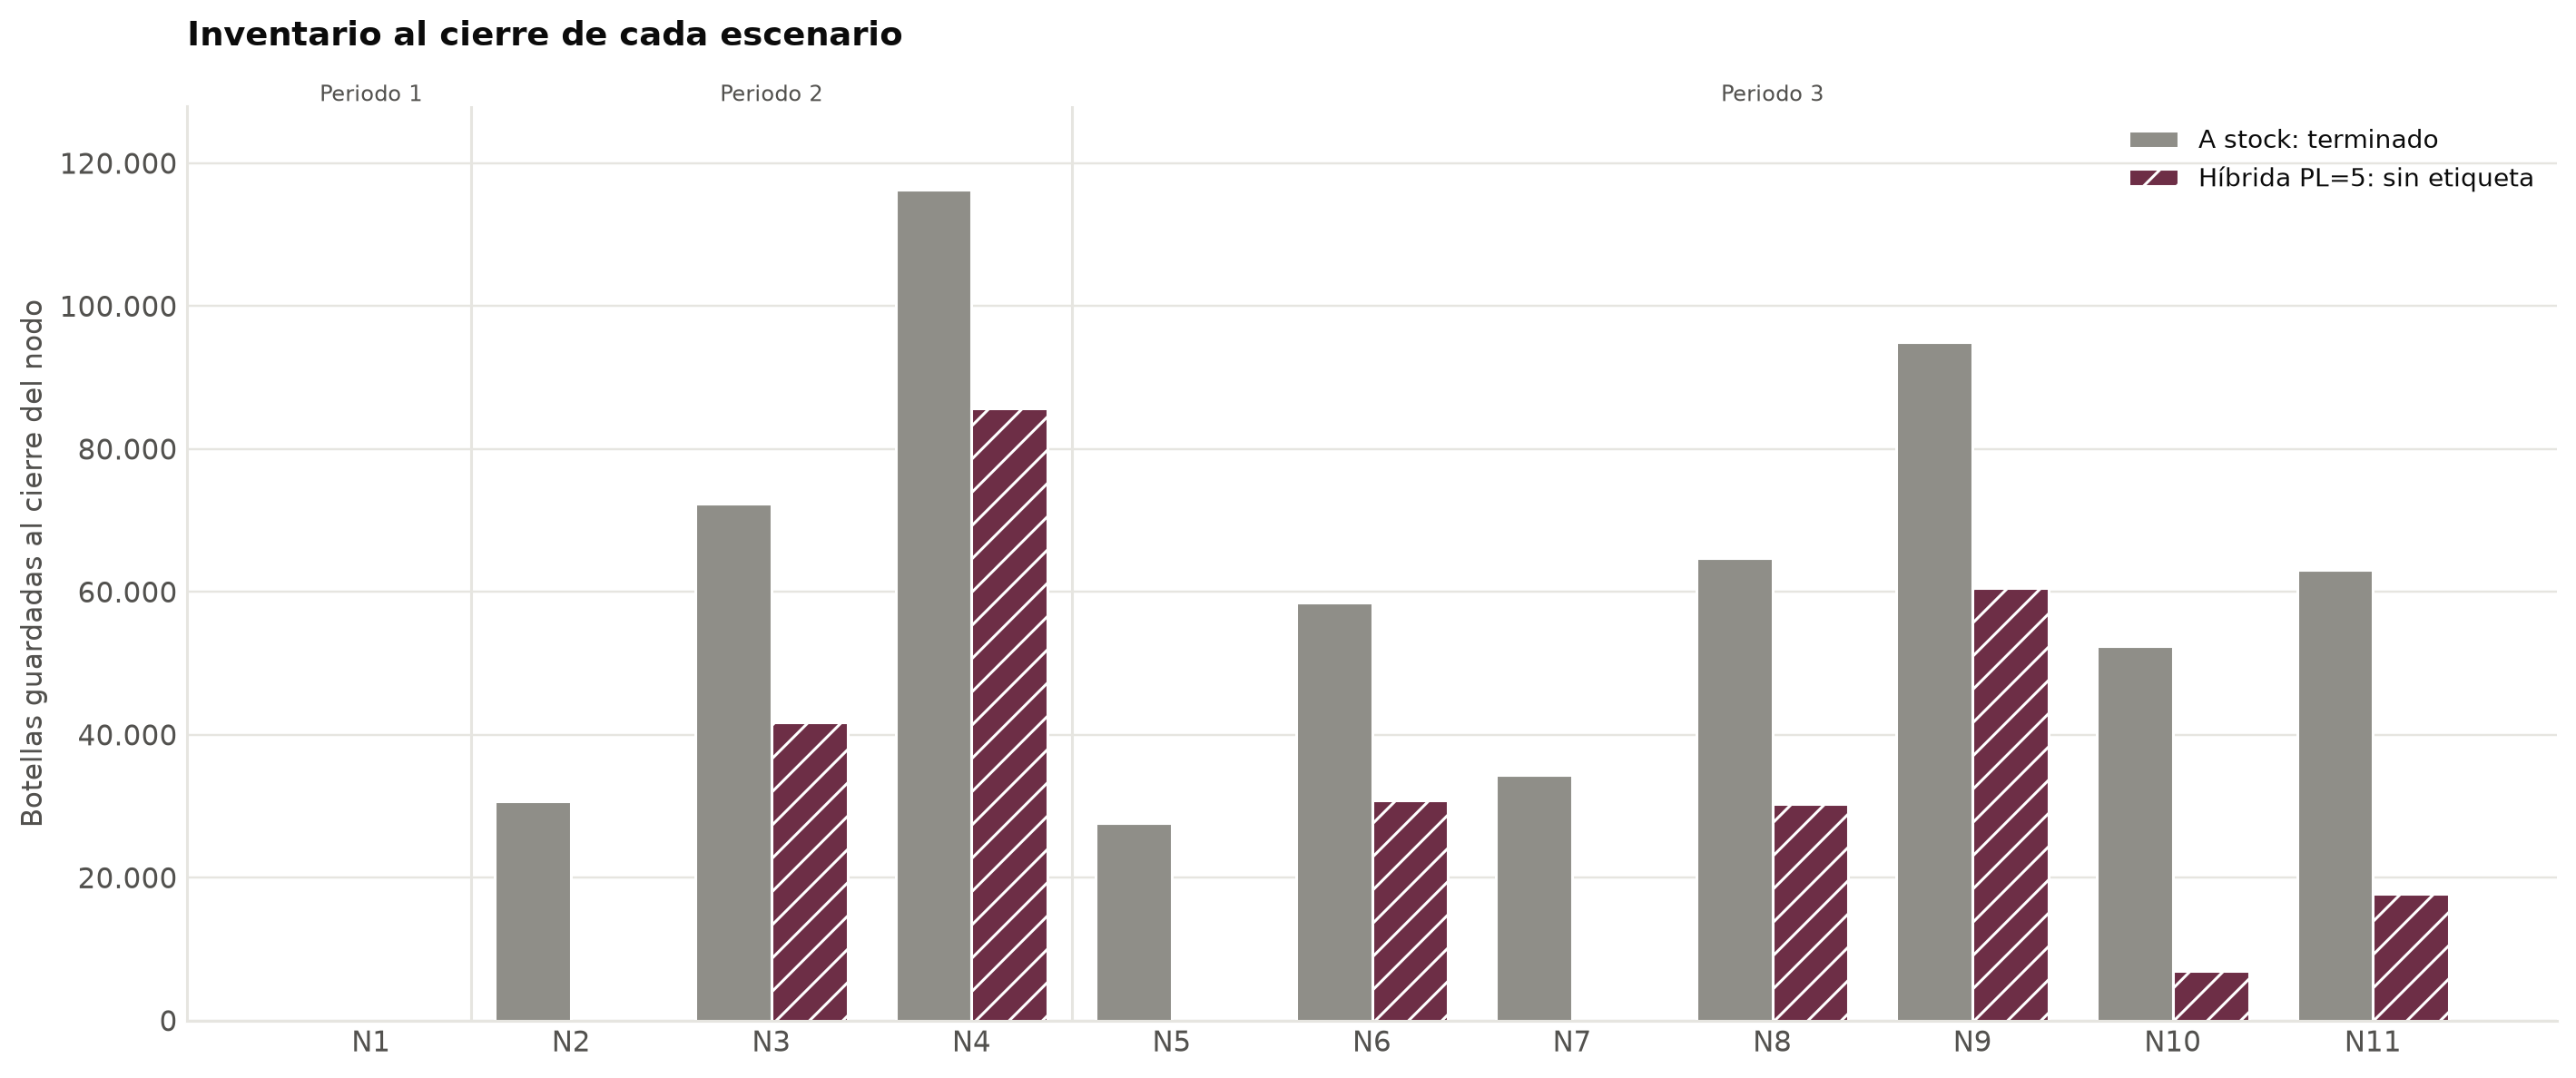

In [10]:
modelo.graficar_inventario_nodos(res_base, res_hib);

En **todos los escenarios** la híbrida guarda menos botellas que *a stock*, y en N2, N5 y N7 no guarda nada. La diferencia más grande está en N10 y N11 (unas 45 mil botellas menos en cada uno). Con *a stock* esas botellas ya tienen una etiqueta que la demanda no pidió.

---
## 6. Conclusiones
1. **Contra pedido no es viable.** Por el rezago de un periodo del embotellado, sin inventario terminado se atrasa el 31 % de la demanda y el costo sube a ~\$1.861 MM, unas 970 veces el caso base. Tener más horas de línea no lo arregla.
2. **La híbrida (PL = 5) reduce el costo esperado en un 68 %**, de \$1,92 MM a \$0,62 MM, **sin perder nivel de servicio** (100 % en ambas).
3. **El ahorro viene del inventario.** Se guardan un 52 % menos botellas (de 42.326 a 20.220 por periodo) y las que se guardan no tienen etiqueta, así que son más baratas y siguen siendo flexibles. El costo de inventario cae de \$1,90 MM a \$0,61 MM.
4. **El precio es más trabajo en la línea.** Los set-ups esperados suben de 9,1 a 13,7 y la utilización media de 43 % a 53 %, pero su costo es marginal (\$10,6 mil). El punto a vigilar es el **nodo 2** (demanda alta), que queda al **98 %** de la capacidad, con muy poca holgura ante imprevistos.

---
## 7. Tiempos de resolución
Tamaño del modelo y tiempo que tarda HiGHS en resolver cada política en nuestro equipo. Los tiempos varían unas décimas de segundo entre ejecuciones.

In [11]:
modelo.tabla_tiempos(tabla)

,Variables,Variables enteras/binarias,Restricciones,Tiempo construcción (s),Tiempo resolución (s),Estado
Política,,,,,,
A stock,445,159,380,"0,01","0,07",Optimal
Híbrida PL=2,445,159,380,"0,01","0,51",Optimal
Híbrida PL=3,445,159,380,"0,01","0,42",Optimal
Híbrida PL=4,445,159,380,"0,01","0,52",Optimal
Híbrida PL=5,445,159,380,"0,01","1,41",Optimal
Contra pedido,445,159,435,"0,01","0,04",Optimal


In [12]:
modelo.info_equipo()

,Equipo
Procesador,AMD Ryzen 7 8840HS w/ Radeon 780M Graphics (8 ...
Memoria RAM,"15,3 GB"
Sistema operativo,Windows 11
Python,3.13.3
PuLP / HiGHS,3.3.0 / 1.15.1


---
---
# Anexo
## A.1 Datos de la instancia (Anexo A)
Cada nodo es un escenario posible. Su probabilidad **π** es el producto de las probabilidades condicionales desde la raíz (nodo 1).

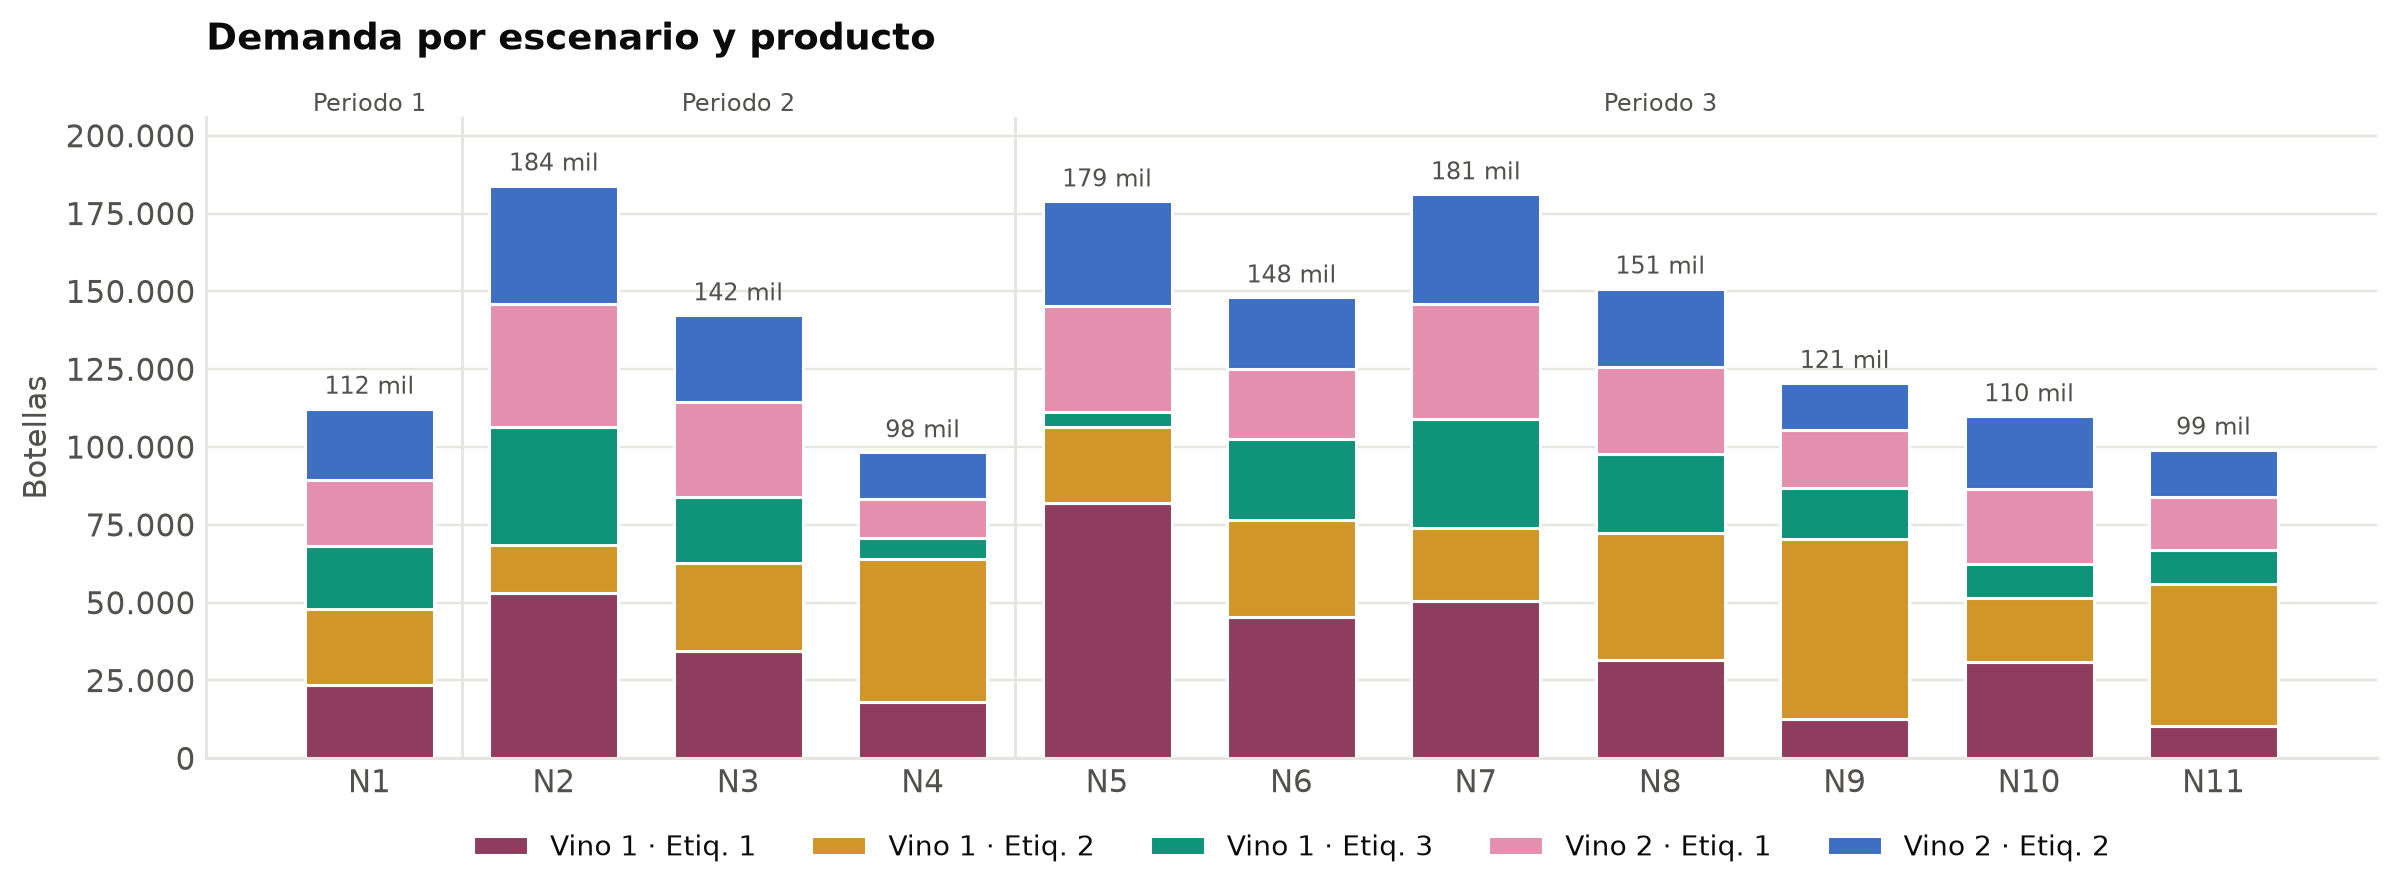

In [13]:
modelo.graficar_demanda();

In [14]:
arbol = pd.DataFrame({'Periodo': modelo._periodos(datos.PADRE), 'Nodo padre': datos.PADRE, 'Probabilidad π': datos.PROB})
arbol['Nodo padre'] = arbol['Nodo padre'].map(lambda p: '—' if pd.isna(p) else f'N{int(p)}')
demanda = pd.Series(datos.DEM).unstack(2)
demanda.index = [modelo._nombre_producto(i, j) for i, j in demanda.index]
demanda.columns = [f'N{n}' for n in demanda.columns]
display(arbol.rename_axis('Nodo').style.format({'Probabilidad π': '{:.3f}'}))
display(demanda.style.format(modelo._num).set_caption('Demanda (botellas) por producto y nodo'))

,Periodo,Nodo padre,Probabilidad π
Nodo,,,
1,1,—,1.000
2,2,N1,0.300
3,2,N1,0.400
4,2,N1,0.300
5,3,N2,0.210
6,3,N2,0.090
7,3,N3,0.133
8,3,N3,0.133
9,3,N3,0.133


,N1,N2,N3,N4,N5,N6,N7,N8,N9,N10,N11
Vino 1 · Etiq. 1,23.525,53.218,34.328,18.118,81.856,45.302,50.426,31.482,12.538,30.856,10.426
Vino 1 · Etiq. 2,24.328,15.184,28.525,45.832,24.546,31.371,23.569,40.767,57.965,20.546,45.569
Vino 1 · Etiq. 3,20.368,38.150,21.080,6.762,4.920,25.765,35.043,25.646,16.248,10.920,11.043
Vino 2 · Etiq. 1,21.080,39.387,30.368,12.646,34.115,22.773,37.045,27.831,18.616,24.115,17.045
Vino 2 · Etiq. 2,22.991,38.048,27.991,14.949,33.440,22.824,35.085,25.147,15.209,23.440,15.085


In [15]:
modelo.tabla_parametros(datos.PARAMS)

,Descripción,Valor
Parámetro,,
T_prod,Horas de línea por periodo,84
K_tank,Estanques disponibles por periodo,20
V_tank,Litros por estanque,10.000
V_bot,Litros por botella,"0,75"
U,Fracción máx. de estanque sin usar,1
Tz_b,Set-up embotellado sin etiqueta (h),"1,5"
Tz_bl,Set-up embotellado + etiquetado (h),"1,5"
Tz_l,Set-up etiquetado posterior (h),"0,5"
Tw_b,Horas por botella sin etiqueta,"0,00014"


## A.2 Decisiones por nodo

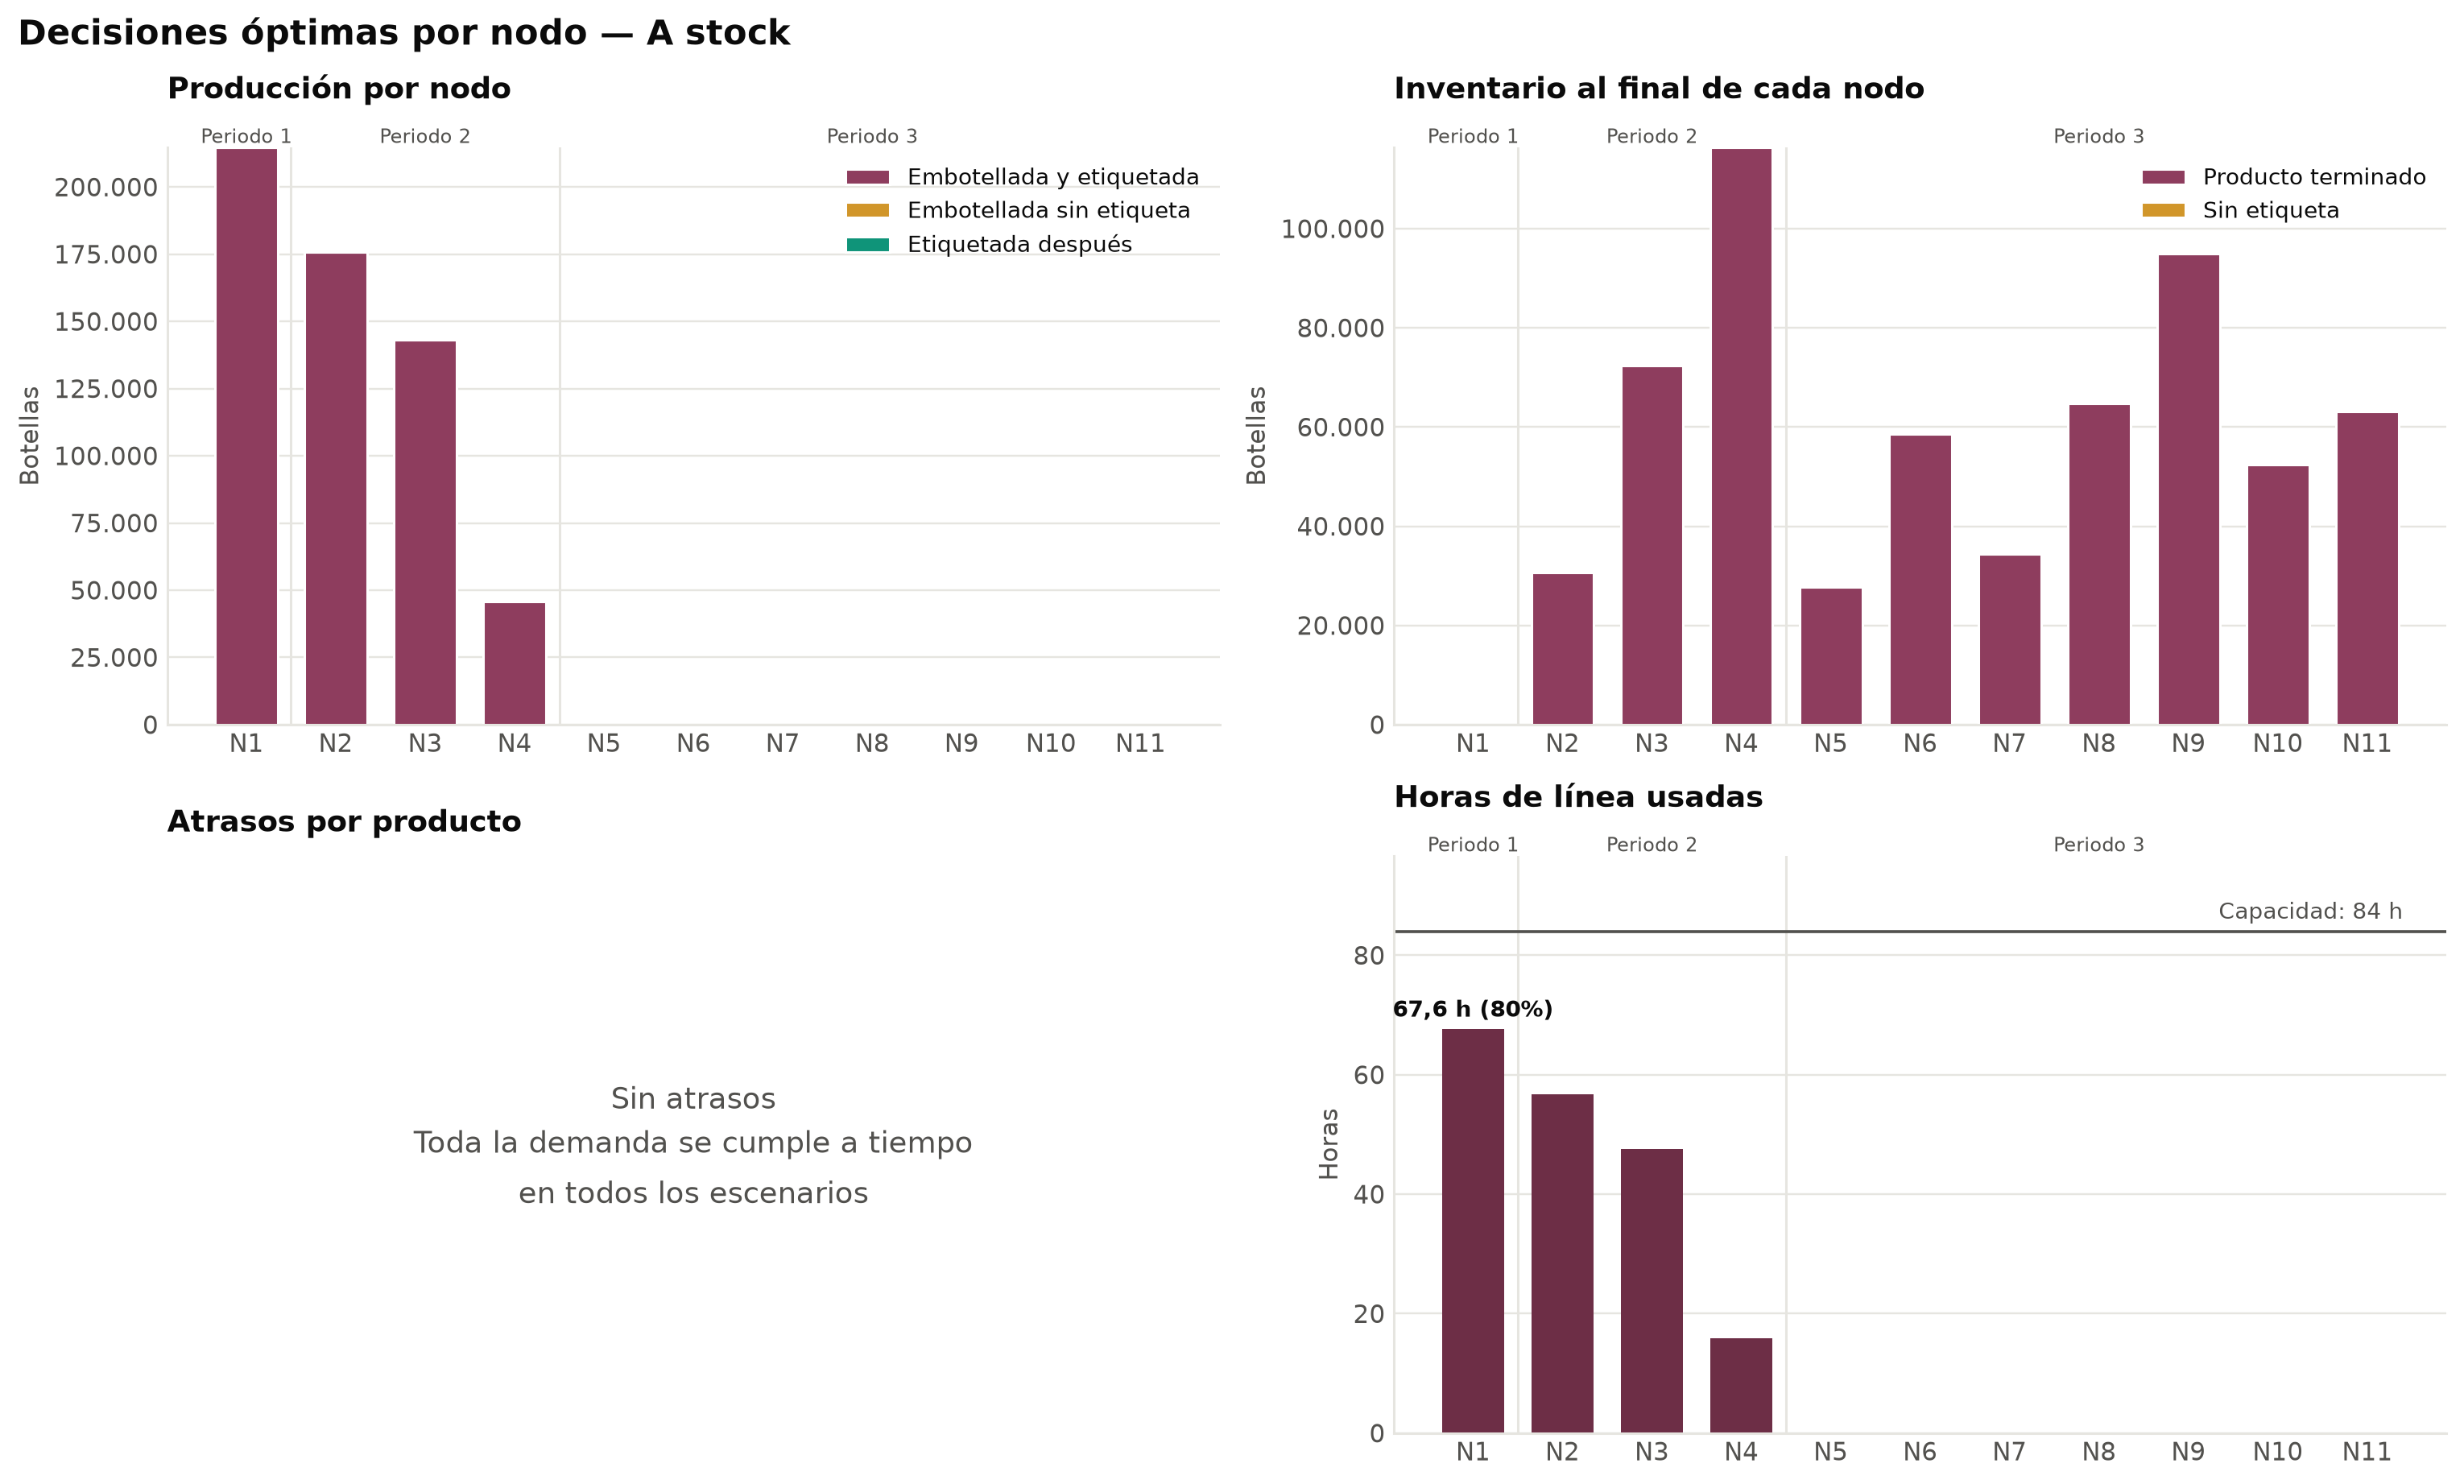

In [16]:
modelo.graficar_decisiones(res_base);

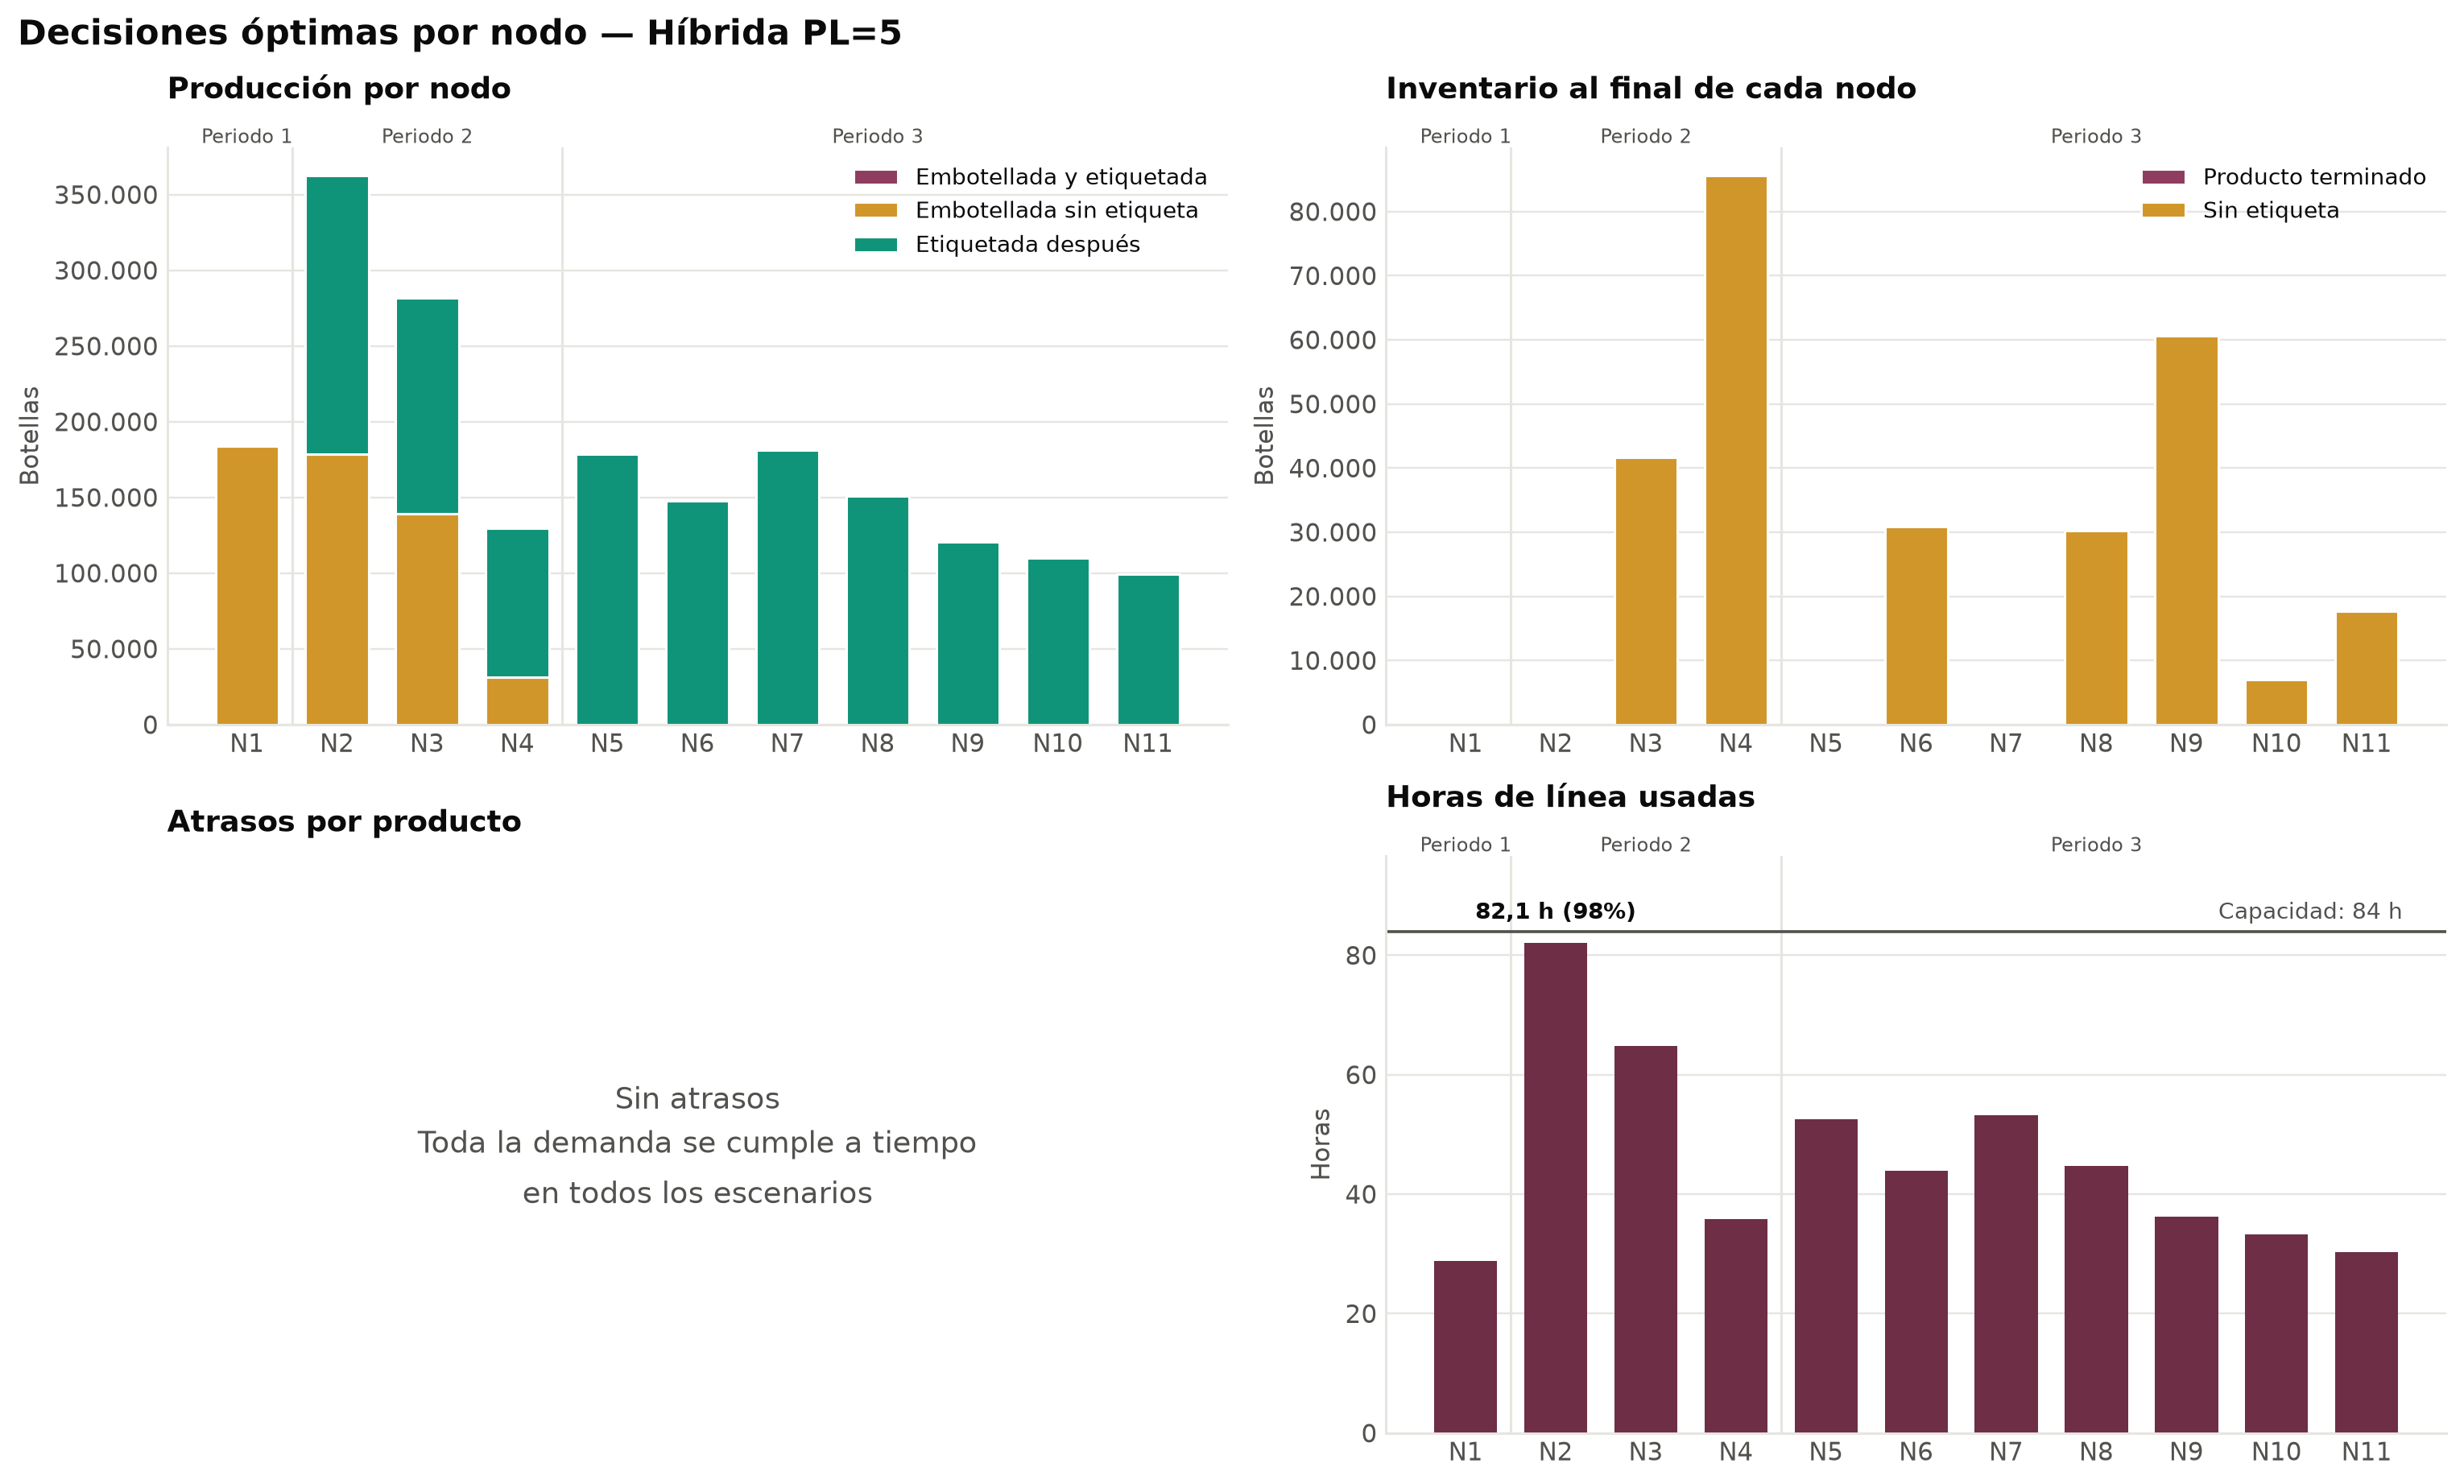

In [17]:
modelo.graficar_decisiones(res_hib);

## A.3 Todas las políticas (PL = 0, 2, 3, 4, 5 y contra pedido)
Se destaca la de menor costo.

In [18]:
modelo.tabla_comparacion(tabla)

,Costo esperado ($),Set-ups ($),Inventario ($),Atrasos ($),vs. A stock,Productos postergables
Política,,,,,,
A stock,1.918.302,13.650,1.904.652,0,—,—
Híbrida PL=2,1.071.131,13.100,1.058.031,0,−44 %,"V1E1, V1E2"
Híbrida PL=3,793.479,11.550,781.929,0,−59 %,"V1E1, V1E2, V1E3"
Híbrida PL=4,704.616,12.550,692.066,0,−63 %,"V1E1, V1E2, V1E3, V2E1"
Híbrida PL=5,617.164,10.550,606.614,0,−68 %,"V1E1, V1E2, V1E3, V2E1, V2E2"
Contra pedido,1.861.097.600,15.000,0,1.861.082.600,+96.918 %,—


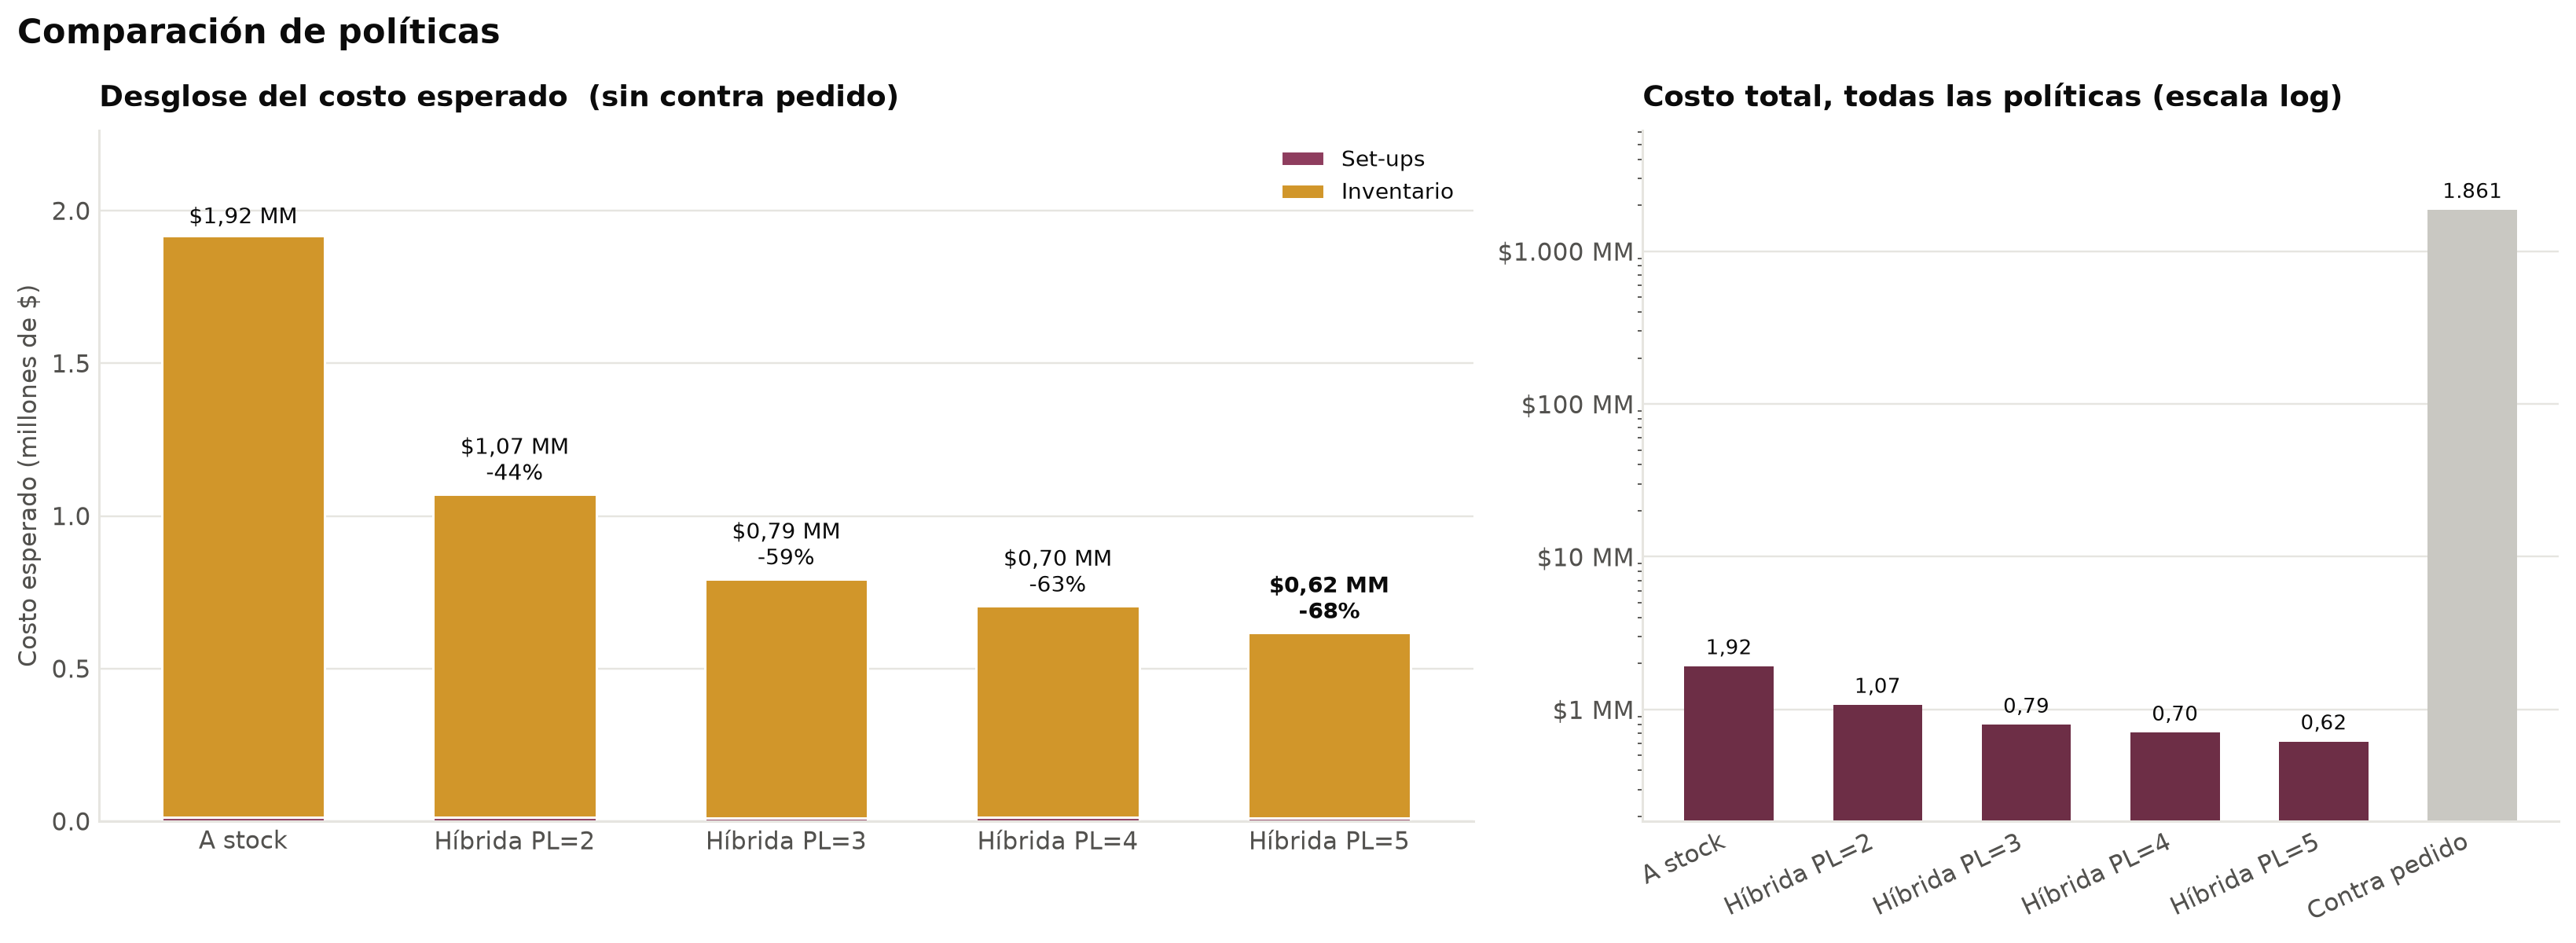

In [19]:
modelo.graficar_comparacion(tabla);

**Los 6 componentes de la función objetivo.** Cada panel tiene su propia escala. *Contra pedido* aparece en gris.

In [20]:
modelo.tabla_costos(tabla)

,A stock,Híbrida PL=2,Híbrida PL=3,Híbrida PL=4,Híbrida PL=5,Contra pedido
Componente ($),,,,,,
Set-up embotellado sin etiqueta,0,3.000,3.000,5.550,5.550,0
Set-up embotellado + etiquetado,13.650,8.100,5.550,3.000,0,15.000
Set-up etiquetado posterior,0,2.000,3.000,4.000,5.000,0
Inventario sin etiqueta,0,77.560,259.054,438.780,606.614,0
Inventario terminado,1.904.652,980.472,522.875,253.286,0,0
Atrasos,0,0,0,0,0,1.861.082.600
Costo total,1.918.302,1.071.131,793.479,704.616,617.164,1.861.097.600


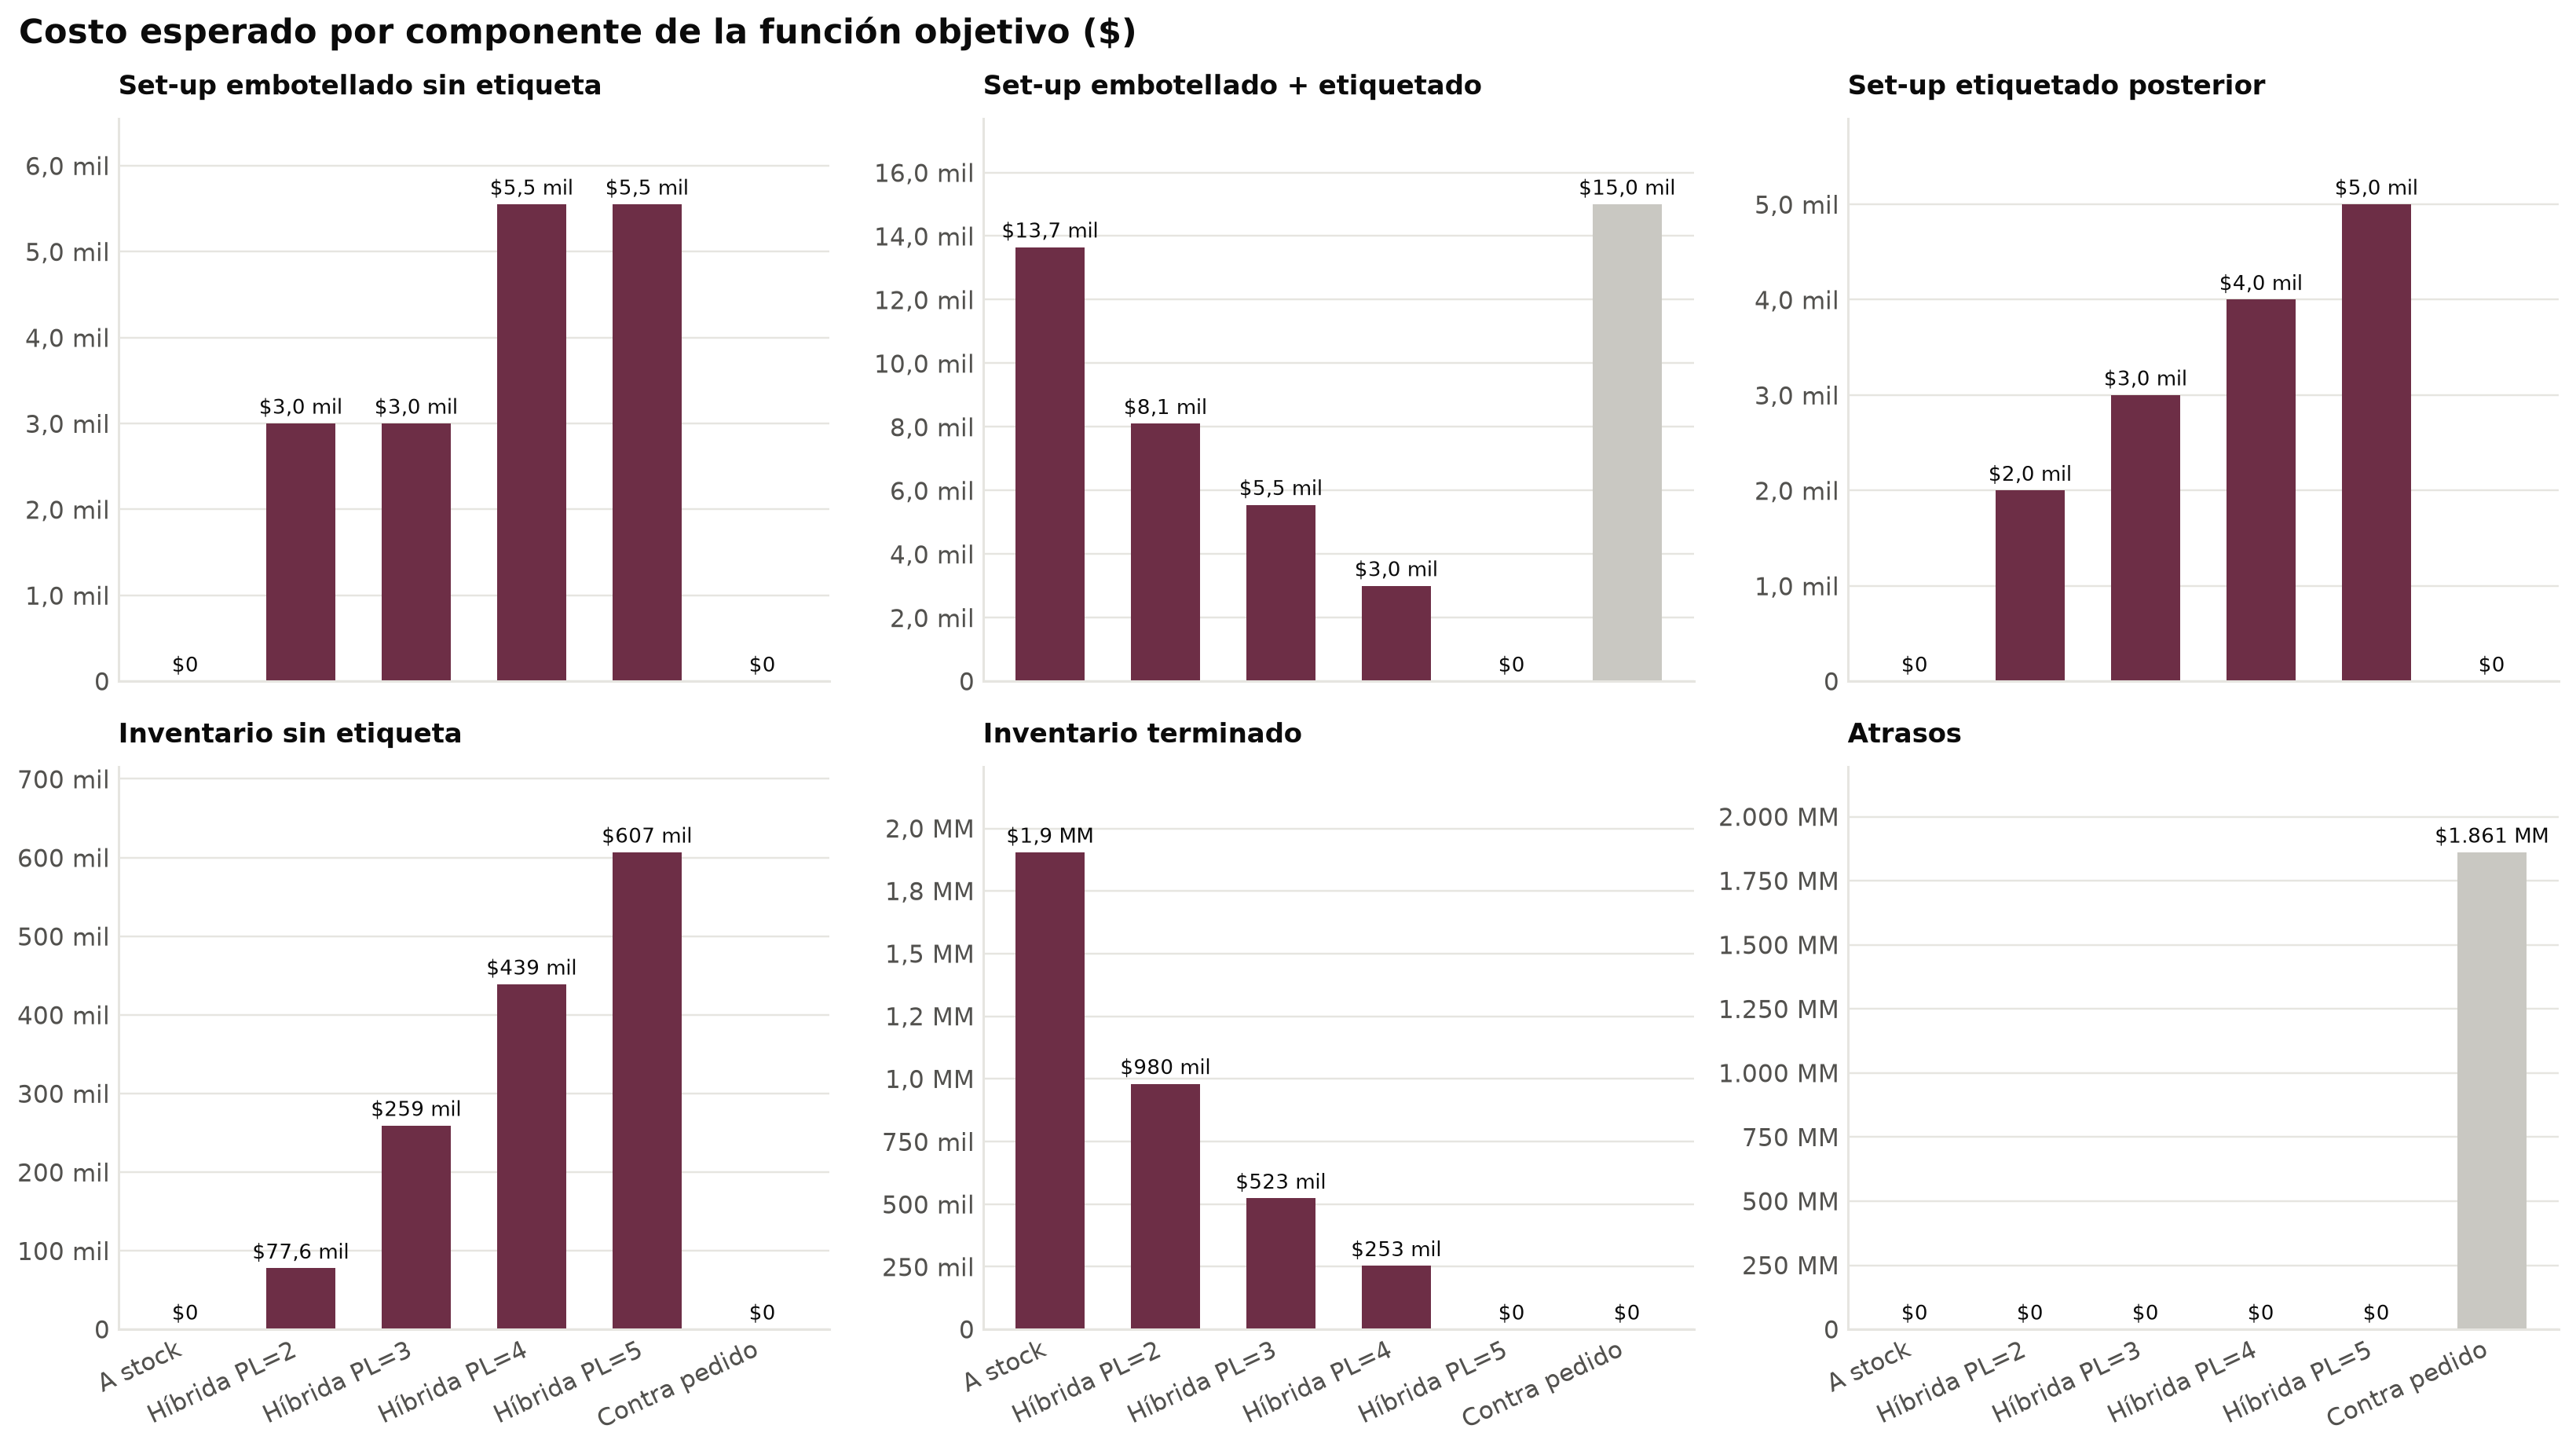

In [21]:
modelo.graficar_costos_detalle(tabla);

**KPIs operativos de todas las políticas**

In [22]:
modelo.tabla_kpis(tabla)

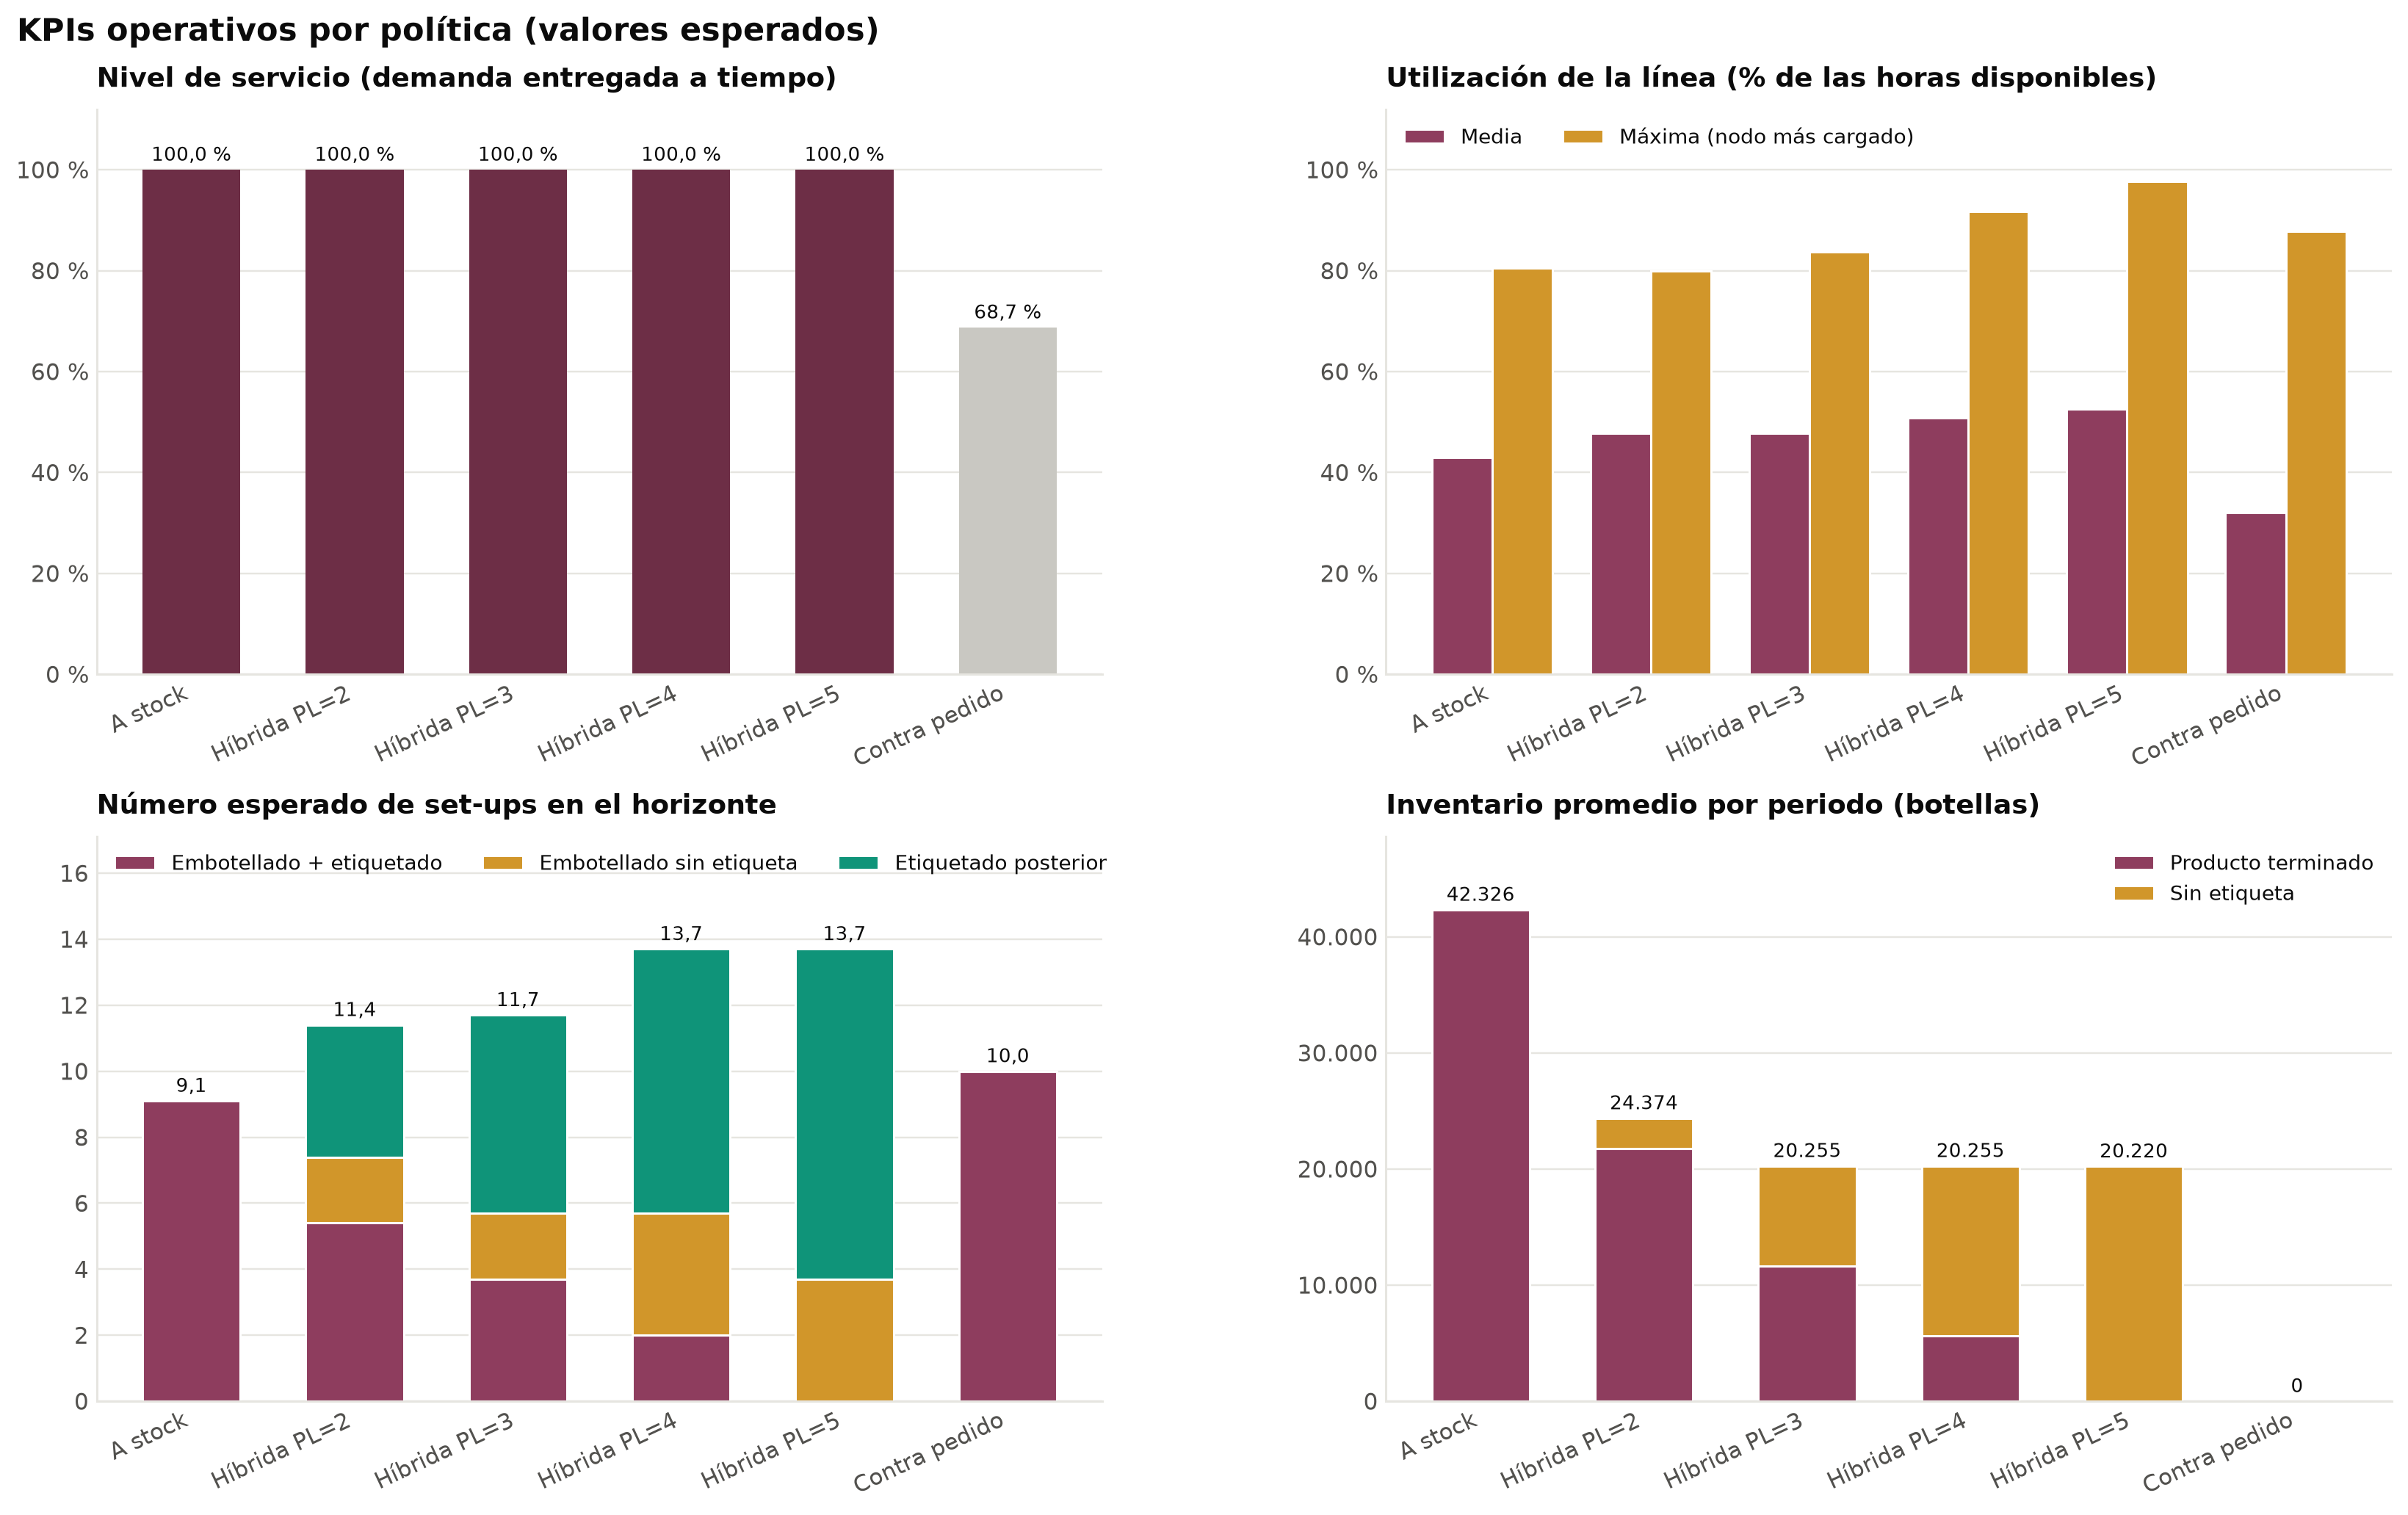

In [23]:
modelo.graficar_kpis(tabla);

## A.4 Sensibilidad a la capacidad de la línea *(próxima entrega)*
Niveles de referencia del Anexo A (sección 6): **21, 42, 63 y 84 horas** por periodo y **0, 2, 3, 4 y 5** etiquetas postergables.

20 modelos resueltos en 53,3 s


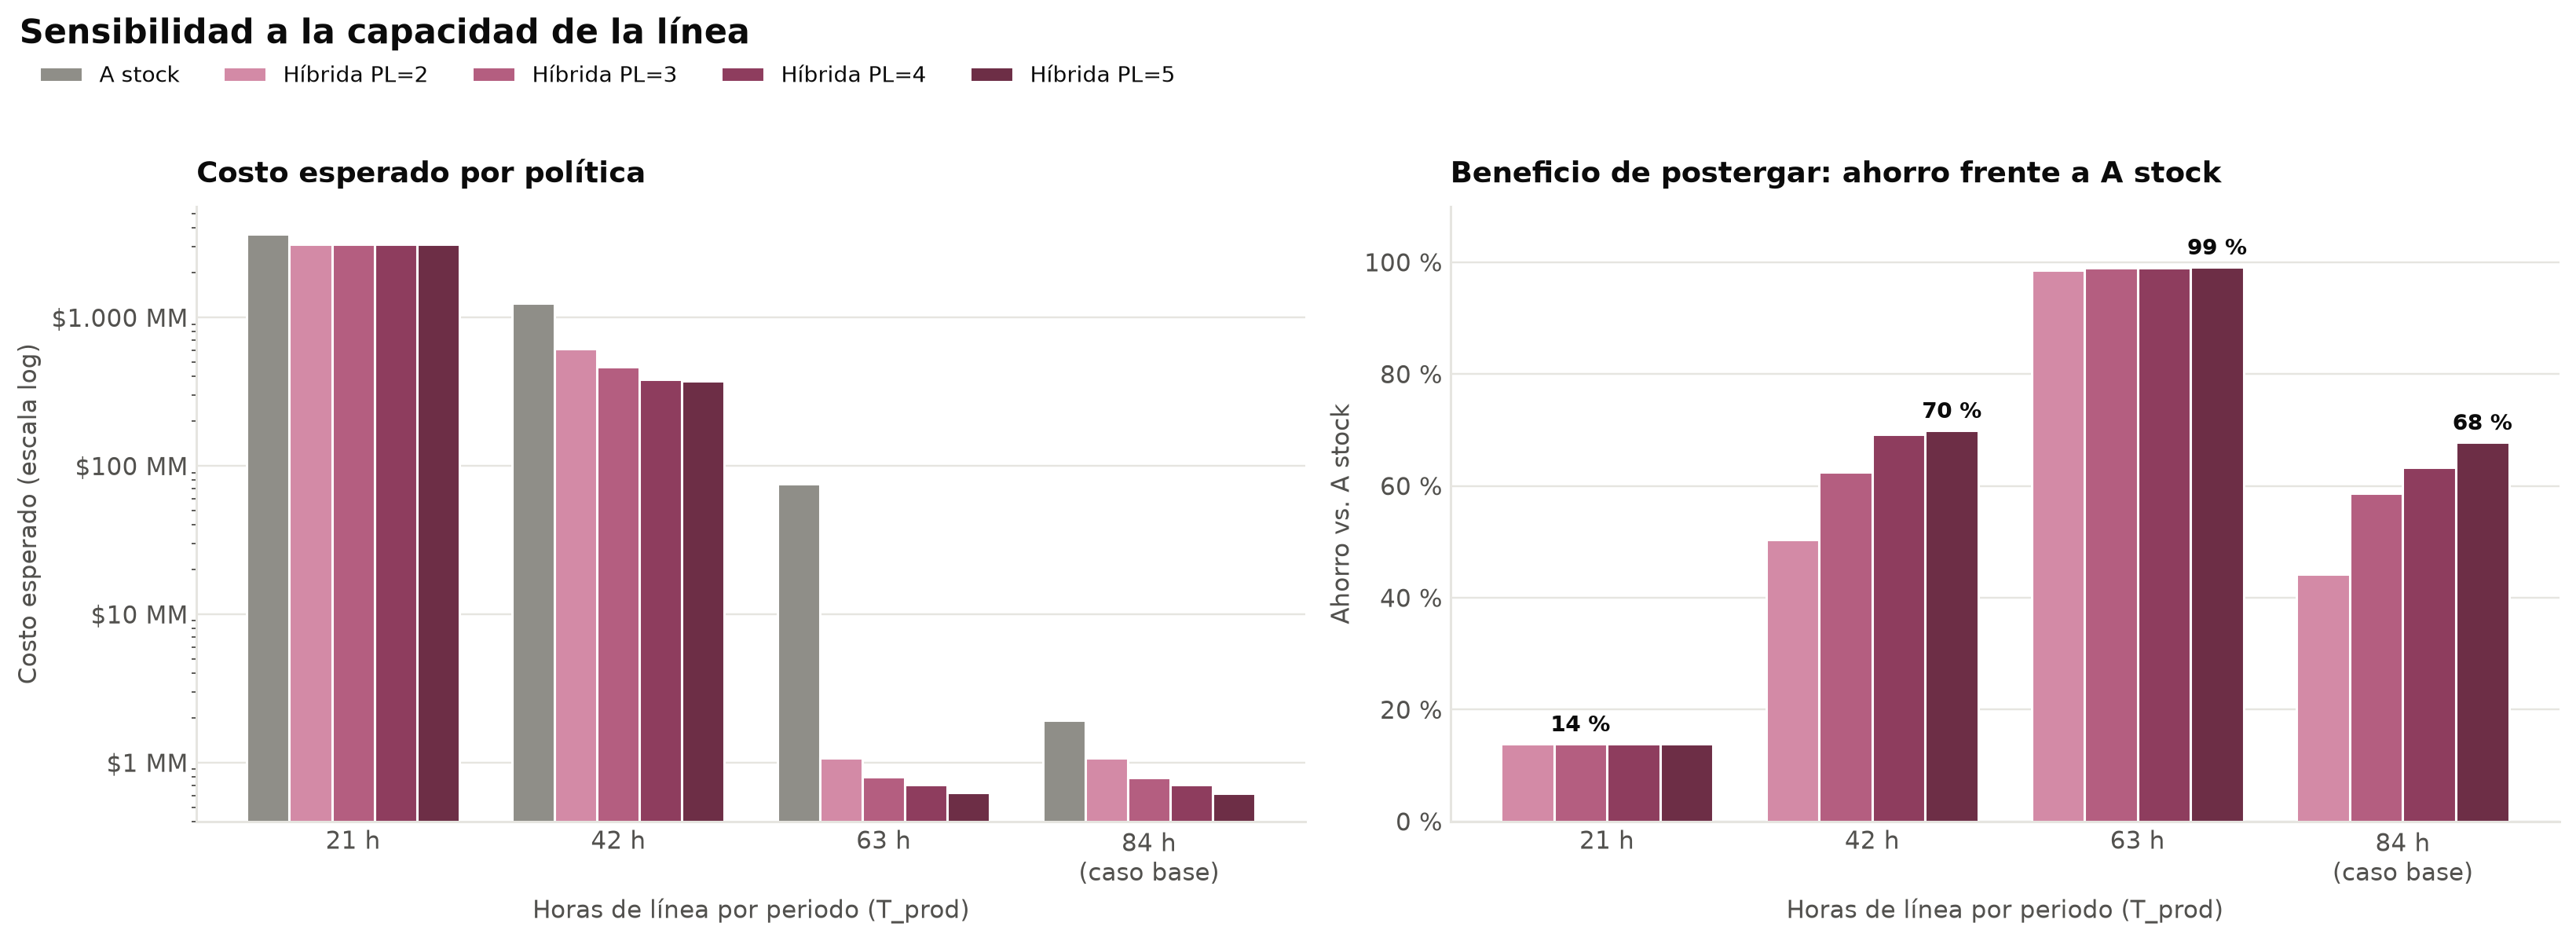

In [24]:
t0 = time.perf_counter()
det = modelo.sensibilidad('T_prod', valores=(21, 42, 63, 84), PLs=(0, 2, 3, 4, 5), detalle=True)
print(f"20 modelos resueltos en {modelo._num(time.perf_counter() - t0, 1)} s")
sens = det['costo'].unstack('politica')[det.index.get_level_values(1).unique()]
modelo.graficar_sensibilidad(sens, base=datos.PARAMS['T_prod']);

In [25]:
(sens / 1e6).style.format(lambda v: modelo._num(v, 2)).set_caption('Costo esperado (millones de $)')

politica,A stock,Híbrida PL=2,Híbrida PL=3,Híbrida PL=4,Híbrida PL=5
T_prod,,,,,
21,"3.628,33","3.123,59","3.123,59","3.123,59","3.123,59"
42,"1.240,13","615,31","465,39","382,11","372,62"
63,"75,57","1,07","0,80","0,71","0,62"
84,"1,92","1,07","0,79","0,70","0,62"


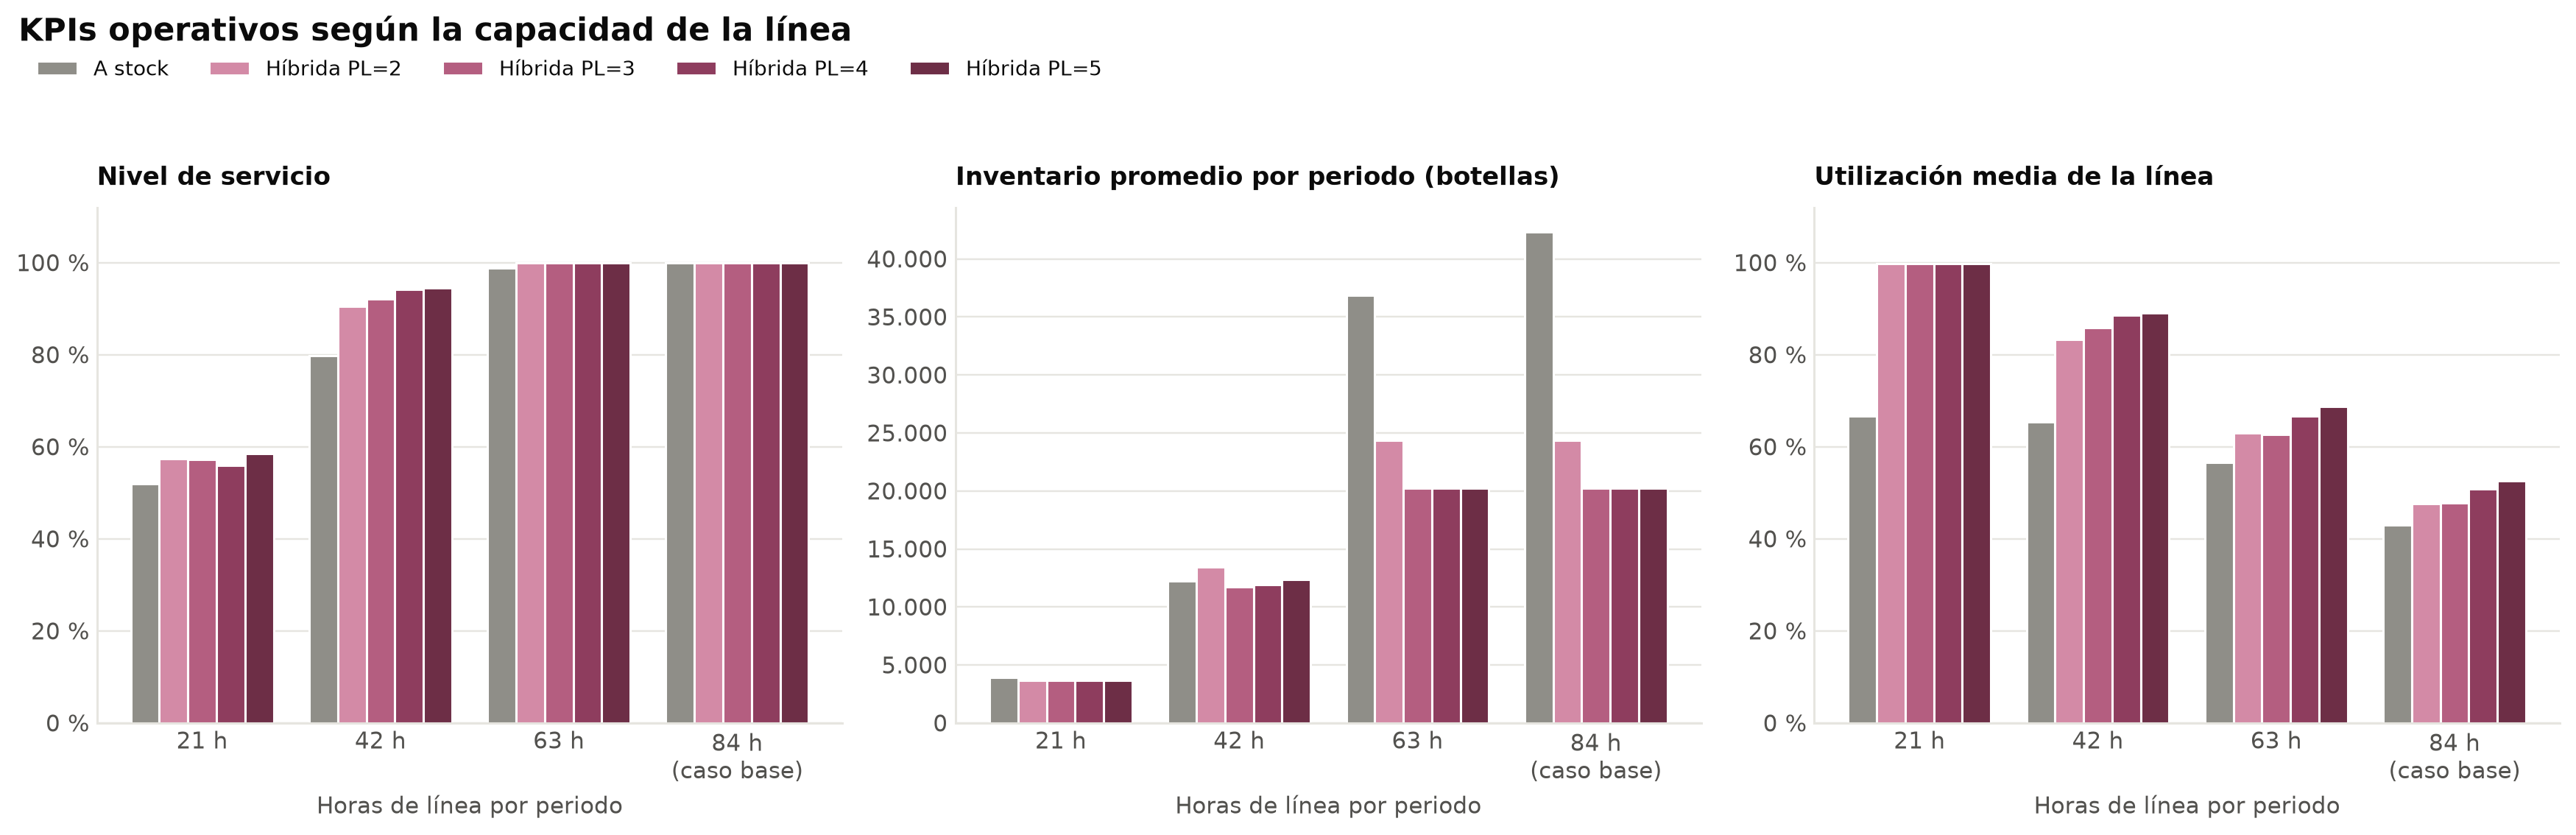

In [26]:
modelo.graficar_sensibilidad_kpis(det, base=datos.PARAMS['T_prod']);

In [27]:
kpis_sens = det[['Nivel de servicio', 'Utilización media', 'Set-ups (total)', 'Inventario promedio (total)']]
kpis_sens.style.format({'Nivel de servicio': modelo._pct, 'Utilización media': modelo._pct,
                        'Set-ups (total)': lambda v: modelo._num(v, 1), 'Inventario promedio (total)': modelo._num})

**Primeras observaciones**
- Con 63 h, *a stock* sube a \$75,6 MM por atrasos, mientras que las híbridas casi no cambian (\$0,6–1,1 MM).
- Con 42 h, *a stock* entrega a tiempo el 80 % de la demanda y *PL = 5* el 94 %.
- Con 21 h la línea no da abasto: el servicio cae a 52–59 % en todas las políticas.